# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
from google.colab import drive
import glob, os
import pandas as pd

drive.mount('/content/drive')

CAMINHO = "/content/drive/MyDrive/Colab Notebooks/diabetes-data.tar.Z"

!mkdir -p /content/diabetes
!tar -xf "{CAMINHO}" -C /content/diabetes

arquivos = sorted(glob.glob('/content/diabetes/**/data-*', recursive=True))
print(len(arquivos), "arquivos encontrados")

dfs = []
for caminho in arquivos:
    tmp = pd.read_csv(
        caminho, sep='\t', header=None,
        names=['data', 'hora', 'codigo', 'valor'],
        on_bad_lines='skip'
    )
    tmp['paciente'] = int(os.path.basename(caminho).split('-')[1])
    dfs.append(tmp)

df = pd.concat(dfs, ignore_index=True)

df['datahora'] = pd.to_datetime(df['data'] + ' ' + df['hora'],
                                format='%m-%d-%Y %H:%M', errors='coerce')
df['valor'] = pd.to_numeric(df['valor'], errors='coerce')
df['codigo'] = pd.to_numeric(df['codigo'], errors='coerce').astype('Int64')

codigos = {
    33: 'insulina_regular', 34: 'insulina_nph', 35: 'insulina_ultralenta',
    48: 'glicemia_nao_especificada', 57: 'glicemia_nao_especificada',
    58: 'glicemia_pre_cafe', 59: 'glicemia_pos_cafe',
    60: 'glicemia_pre_almoco', 61: 'glicemia_pos_almoco',
    62: 'glicemia_pre_jantar', 63: 'glicemia_pos_jantar',
    64: 'glicemia_pre_lanche', 65: 'sintomas_hipoglicemia',
    66: 'refeicao_tipica', 67: 'refeicao_maior', 68: 'refeicao_menor',
    69: 'atividade_tipica', 70: 'atividade_maior', 71: 'atividade_menor',
    72: 'evento_nao_especificado'
}
df['evento'] = df['codigo'].map(codigos)

COD_GLICEMIA = [48, 57, 58, 59, 60, 61, 62, 63, 64]
df['eh_glicemia'] = df['codigo'].isin(COD_GLICEMIA)

df = df.sort_values(['paciente', 'datahora']).reset_index(drop=True)
total_bruto = 0
for caminho in arquivos:
    with open(caminho, 'r', errors='replace') as f:
        total_bruto += sum(1 for linha in f if linha.strip())

print("\n--- Integridade ---")
print(f"Linhas nos arquivos : {total_bruto}")
print(f"Linhas no DataFrame : {len(df)}")
print(f"Linhas descartadas  : {total_bruto - len(df)}")
print(f"Pacientes           : {df['paciente'].nunique()} "
      f"(de {df['paciente'].min()} a {df['paciente'].max()})")
print(f"Datas inválidas     : {df['datahora'].isna().sum()}")
print(f"Valores inválidos   : {df['valor'].isna().sum()}")
print(f"Códigos sem rótulo  : {df['evento'].isna().sum()}")

df.head()

Mounted at /content/drive
70 arquivos encontrados

--- Integridade ---
Linhas nos arquivos : 29330
Linhas no DataFrame : 29330
Linhas descartadas  : 0
Pacientes           : 70 (de 1 a 70)
Datas inválidas     : 45
Valores inválidos   : 52
Códigos sem rótulo  : 154


,data,hora,codigo,valor,paciente,datahora,evento,eh_glicemia
0,04-21-1991,9:09,58,100.0,1,1991-04-21 09:09:00,glicemia_pre_cafe,True
1,04-21-1991,9:09,33,9.0,1,1991-04-21 09:09:00,insulina_regular,False
2,04-21-1991,9:09,34,13.0,1,1991-04-21 09:09:00,insulina_nph,False
3,04-21-1991,17:08,62,119.0,1,1991-04-21 17:08:00,glicemia_pre_jantar,True
4,04-21-1991,17:08,33,7.0,1,1991-04-21 17:08:00,insulina_regular,False


## 1. Princípio Estrutural

Antes de sair analisando, vale entender como esses dados são, tipo quantas linhas e colunas, que tipo de informação cada coluna guarda, se tem valor faltando, se tem linha repetida.

Só que tem um detalhe antes de rodar o código. O Diabetes não se parece com aqueles datasets clínicos certinhos em formato de tabela. Não é como no cardiaco, onde tipo tem uma linha por paciente com várias variáveis preditoras. Cada linha é um **evento registrado**: data, hora, código do evento e valor. São 70 pacientes com diabetes tipo 1 acompanhados ao longo de meses, entre 1988 e 1991. Ou seja, o mesmo paciente aparece centenas de vezes. E não existe uma variável alvo pronta, tipo o 'num' do Heart Disease. A categoria que interessa vai ter que ser construída a partir das próprias medições de glicemia.

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(29330, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29330 entries, 0 to 29329
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   data         29297 non-null  object        
 1   hora         29330 non-null  object        
 2   codigo       29330 non-null  Int64         
 3   valor        29278 non-null  float64       
 4   paciente     29330 non-null  int64         
 5   datahora     29285 non-null  datetime64[ns]
 6   evento       29176 non-null  object        
 7   eh_glicemia  29330 non-null  boolean       
dtypes: Int64(1), boolean(1), datetime64[ns](1), float64(1), int64(1), object(3)
memory usage: 1.7+ MB


In [ ]:
df.describe()

,codigo,valor,paciente,datahora
count,29330.0,29278.000000,29330.000000,29285
mean,46.428606,79.374906,36.435152,1990-08-19 13:08:52.400887808
min,0.0,0.000000,1.000000,1988-03-27 08:00:00
25%,33.0,6.000000,21.000000,1990-01-03 07:00:00
50%,48.0,24.000000,34.000000,1990-09-20 07:00:00
75%,60.0,142.000000,55.000000,1991-05-08 05:35:00
max,72.0,501.000000,70.000000,1991-09-23 21:10:00
std,13.453219,93.496915,20.101179,NaN


### Duplicadas

In [ ]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()


np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original não vem com uma variável alvo, porque cada linha é um evento registrado e não um paciente diagnosticado. Então hoje a gente vai construir essa variável a partir das próprias medições de glicemia, que no fim é a grandeza clínica que interessa aqui.

A ideia é criar uma variável binária, tipo tem ou não tem hiperglicemia, usando o corte de 180 mg/dL, que é o limiar padrão de *time in range* em diabetes. É essa distinção que vai aparecer nas cores durante a aula (rosa = normal, roxo = hiperglicemia).

Além dessa, guardamos também uma versão com três faixas: hipoglicemia abaixo de 70, na meta entre 70 e 180, e hiperglicemia acima de 180. Vai ser útil quando a gente quiser descrever o quadro com mais detalhe.

In [ ]:

df.loc[df['eh_glicemia'] & (df['valor'] <= 0), 'valor'] = np.nan
glic = df[df['eh_glicemia'] & df['valor'].notna()].copy()
glic['hiperglicemia'] = np.where(glic['valor'] > 180, 'Hiperglicemia', 'Normal')
glic['faixa_glicemia'] = pd.cut(
    glic['valor'],
    bins=[0, 70, 180, np.inf],
    labels=['Hipoglicemia', 'Na meta', 'Hiperglicemia'],
    right=False
)

print(glic['hiperglicemia'].value_counts(), "\n")
print(glic['faixa_glicemia'].value_counts(), "\n")
print("Medições de glicemia:", len(glic), "de", len(df), "eventos totais")

glic.head()

hiperglicemia
Normal           8647
Hiperglicemia    4875
Name: count, dtype: int64 

faixa_glicemia
Na meta          7017
Hiperglicemia    4932
Hipoglicemia     1573
Name: count, dtype: int64 

Medições de glicemia: 13522 de 29285 eventos totais


,data,hora,codigo,valor,paciente,datahora,evento,eh_glicemia,hiperglicemia,faixa_glicemia
0,04-21-1991,9:09,58,100.0,1,1991-04-21 09:09:00,glicemia_pre_cafe,True,Normal,Na meta
3,04-21-1991,17:08,62,119.0,1,1991-04-21 17:08:00,glicemia_pre_jantar,True,Normal,Na meta
5,04-21-1991,22:51,48,123.0,1,1991-04-21 22:51:00,glicemia_nao_especificada,True,Normal,Na meta
6,04-22-1991,7:35,58,216.0,1,1991-04-22 07:35:00,glicemia_pre_cafe,True,Hiperglicemia,Hiperglicemia
10,04-22-1991,16:56,62,211.0,1,1991-04-22 16:56:00,glicemia_pre_jantar,True,Hiperglicemia,Hiperglicemia


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
data,17
hora,0
codigo,0
valor,31
paciente,0
datahora,29
evento,132
eh_glicemia,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim, alguns faltam dtas, outros valor, outras as horas e outra o evento em si.... Delas só a de evento que é "Esperada" e tal... pq a pessoa pode nao ter nada

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos quatro features com dados ausentes: 'data', 'valor', 'datahora' e 'evento'. Duas são ausências reais na fonte e duas são derivadas do processamento.

Pela fonte de dados observamos que:

* data / hora - momento do registro, transcrito do diário do paciente ou gerado automaticamente pelo aparelho
* valor - a medição em si (glicemia em mg/dL ou dose de insulina em unidades, conforme o código)
* datahora - coluna derivada, criada pela junção de *data* + *hora*
* evento - coluna derivada, criada pelo mapeamento do código numérico para o rótulo textual

*Como os dados foram coletados:*
- Os registros vêm de 70 pacientes com diabetes tipo 1, acompanhados entre 1988 e 1991. A coleta se deu por duas vias distintas: registros eletrônicos automáticos, gerados por aparelhos de medição com data e hora corretas, e registros em papel, preenchidos à mão pelos pacientes e depois transcritos.
- Nos arquivos em papel, os horários eram padronizados na digitação (café da manhã 08:00, almoço 12:00, jantar 18:00, ao deitar 22:00), justamente porque o horário real nem sempre era anotado pelo paciente.

*Qual a natureza da fonte de dados:*
- A dupla origem explica a maior parte das ausências: a transcrição manual de diários preenchidos ao longo de meses está sujeita a erro de digitação, campos ilegíveis e anotações incompletas. Daí surgem as datas em branco e as horas malformadas.
- *valor* ausente indica medição que o paciente não anotou ou que se perdeu na transcrição, limitação inerente a estudos com autorregistro, em que a adesão ao preenchimento varia ao longo do tempo.
- *evento* ausente não é falha de coleta: são códigos numéricos fora da tabela oficial de 20 códigos do UCI, provavelmente erros de digitação ou códigos internos usados pelos pesquisadores e não documentados na publicação.
- *datahora* ausente é consequência das duas primeiras: onde *data* faltava ou onde a hora estava malformada, a conversão para datetime falhou.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['data', 'valor', 'datahora', 'evento']
data         17
valor        31
datahora     29
evento      132
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

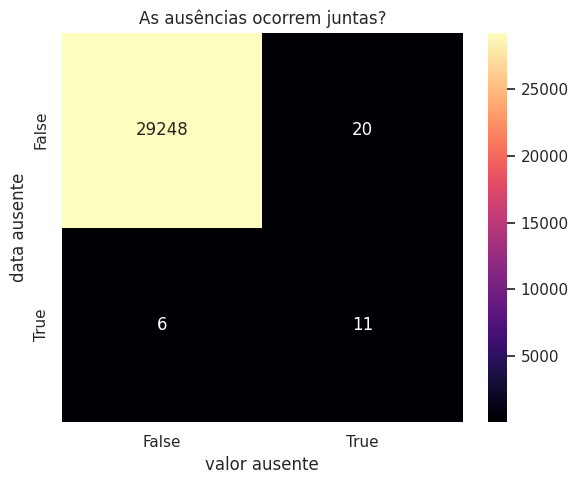

In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
col_a, col_b = cols_com_ausentes[0], cols_com_ausentes[1]

tabela_contingencia = pd.crosstab(
    df[col_a].isna(), df[col_b].isna(),
    rownames=[f"{col_a} ausente"], colnames=[f"{col_b} ausente"]
)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Interpretação**

Se as duas ausências fossem independentes, a gente esperaria mais ou menos 0,02 linha com as duas faltando ao mesmo tempo. E observamos 11. Ou seja, a coincidência é ordens de grandeza maior do que o acaso explicaria, o que já indica um padrão sistemático e não aleatório.

A explicação mais provável é corrupção em nível de linha. Quando um registro do diário em papel estava ilegível ou foi cortado na hora de transcrever, o registro inteiro se perdeu de uma vez só, e não campo por campo.

Isso ajuda a refinar a classificação do mecanismo. Não é MCAR puro, já que as ausências não são independentes entre si: a falta de *valor* dá pra prever a partir da falta de *data*, porque as duas vêm da mesma causa. Por outro lado, a ausência não depende do valor que estaria ali (uma glicemia alta não tinha mais chance de sumir), então jogar essas linhas fora não introduz viés na distribuição.

O heatmap original usava escala linear, e aí a célula de 29.248 domina a paleta inteira e deixa as três células que interessam indistinguíveis. Na versão em escala logarítmica dá pra enxergar a comparação.

--- As duas ausências coincidem por acaso? ---
Linhas totais           : 29285
'data' ausente          : 17
'valor' ausente         : 31
Esperado se independente: 0.018 linha(s)
Observado               : 11 linha(s)
Razao observado/esperado: 611x

Ausências por paciente:
paciente
29    24
2      7
27     4
9      1
40     1
Name: count, dtype: int64 

Pacientes afetados: 5 de 70

Linhas com 'data' e 'valor' ausentes ao mesmo tempo:
      data hora  codigo  valor  paciente datahora            evento  \
10078  NaN  138      33    NaN        27      NaT  insulina_regular   
12291  NaN  201      33    NaN        29      NaT  insulina_regular   
12294  NaN  202      33    NaN        29      NaT  insulina_regular   
12297  NaN  195      33    NaN        29      NaT  insulina_regular   
12300  NaN  168      33    NaN        29      NaT  insulina_regular   
12303  NaN  226      33    NaN        29      NaT  insulina_regular   
12306  NaN  162      33    NaN        29      NaT  insulina_regular

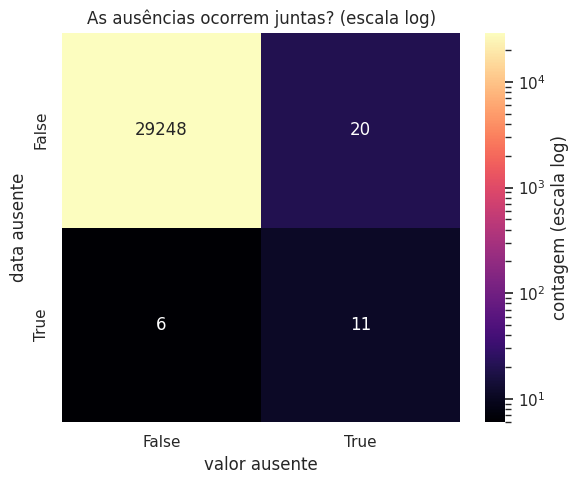

In [ ]:
n = len(df)
n_data = df['data'].isna().sum()
n_valor = df['valor'].isna().sum()

observado = (df['data'].isna() & df['valor'].isna()).sum()
esperado = n_data * n_valor / n

print("--- As duas ausências coincidem por acaso? ---")
print(f"Linhas totais           : {n}")
print(f"'data' ausente          : {n_data}")
print(f"'valor' ausente         : {n_valor}")
print(f"Esperado se independente: {esperado:.3f} linha(s)")
print(f"Observado               : {observado} linha(s)")
print(f"Razao observado/esperado: {observado/esperado:.0f}x\n")

faltantes = df[df['data'].isna() | df['valor'].isna()]
print("Ausências por paciente:")
print(faltantes['paciente'].value_counts(), "\n")
print(f"Pacientes afetados: {faltantes['paciente'].nunique()} de {df['paciente'].nunique()}\n")

print("Linhas com 'data' e 'valor' ausentes ao mesmo tempo:")
print(df[df['data'].isna() & df['valor'].isna()])

from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma",
            norm=LogNorm(), ax=ax, cbar_kws={'label': 'contagem (escala log)'})
ax.set_title("As ausências ocorrem juntas? (escala log)")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se a gente supõe que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se desconfiava, por sinais clínicos observados antes, que o resultado ia dar anormal, e aí o exame extra não seria necessário. Nesse caso seria **MNAR**.
- *Se a gente supõe que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não pedir aquele exame, ou o custo do procedimento limitou a coleta, independente de qual seria o resultado. Aí seria **MAR**, ou até **MCAR**, se a decisão for arbitrária e não sistemática.

Só olhando os dados não dá pra decidir entre as duas. É exatamente o tipo de situação em que testes estatísticos (tipo o teste de MCAR) e conhecimento de domínio de verdade, tipo falar com quem coletou os dados, resolveriam a dúvida. Sem isso, a gente segue com a opção mais conservadora na hora de tratar.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = ["valor"]
VARS_QUALI = ["evento", "paciente", "eh_glicemia"]

base = df[df["valor"].notna() & df["evento"].notna()].copy()


desc = base.groupby("evento")["valor"].describe()
desc["skewness"] = base.groupby("evento")["valor"].skew()
desc["kurtosis"] = base.groupby("evento")["valor"].apply(pd.Series.kurtosis)

(
    desc[["count", "mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .sort_values("count", ascending=False)
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,count,mean,median,std,min,max,skewness,kurtosis
evento,,,,,,,,
insulina_regular,9487.00,6.63,6.00,5.43,0.00,344.00,26.32,1580.03
insulina_nph,3830.00,15.39,15.00,14.16,1.00,388.00,10.49,218.60
glicemia_pre_cafe,3518.00,170.70,161.00,77.74,23.00,461.00,0.51,-0.27
glicemia_pre_jantar,3158.00,156.38,147.00,74.10,28.00,450.00,0.68,0.21
glicemia_nao_especificada,2870.00,167.39,156.00,86.26,19.00,501.00,0.75,0.30
glicemia_pre_almoco,2768.00,143.56,134.00,74.56,15.00,452.00,0.93,0.81
insulina_ultralenta,1053.00,15.86,15.00,7.81,3.00,30.00,0.32,-0.84
glicemia_pre_lanche,903.00,148.94,125.00,86.64,28.00,461.00,0.87,0.13
sintomas_hipoglicemia,328.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


,count,mean,median,std,min,max,skewness,kurtosis
valor,13522.0,160.26,149.0,80.15,15.0,501.0,0.72,0.21


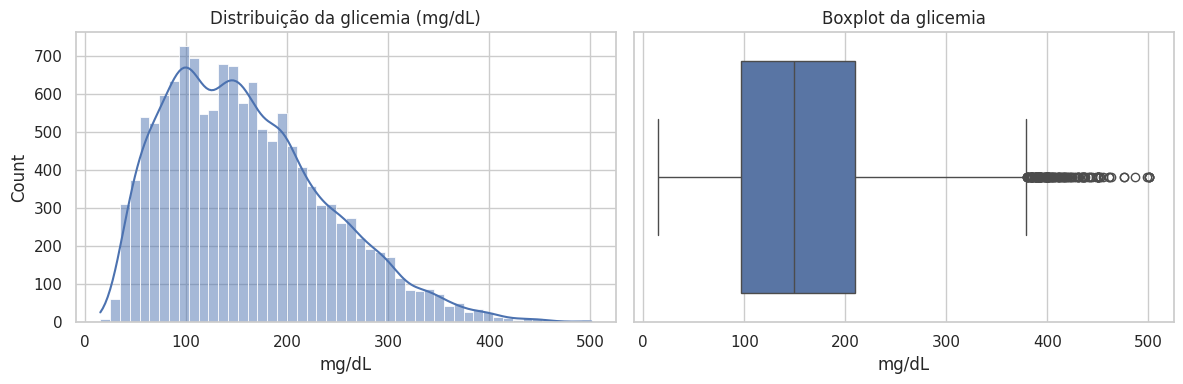

In [ ]:
glic = df[df["eh_glicemia"] & df["valor"].notna() & (df["valor"] > 0)].copy()

desc_g = glic["valor"].describe().to_frame().T
desc_g["skewness"] = glic["valor"].skew()
desc_g["kurtosis"] = glic["valor"].kurtosis()

display(
    desc_g[["count", "mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(glic["valor"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Distribuição da glicemia (mg/dL)")
ax[0].set_xlabel("mg/dL")
sns.boxplot(x=glic["valor"], ax=ax[1])
ax[1].set_title("Boxplot da glicemia")
ax[1].set_xlabel("mg/dL")
plt.tight_layout()
plt.show()

**Pra discutir:** olhando a tabela por tipo de evento, quais eventos já parecem assimétricos (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Na glicemia sozinha temos `skewness` de 0,72 e `kurtosis` de 0,21. Ou seja, assimetria positiva moderada, mas sem uma cauda tão pesada quanto aquela nuvem de outliers do boxplot dá a entender de cara. A média (160,3 mg/dL) fica acima da mediana (149,0), o que confirma a cauda puxando pra direita.

Isso bate com o que vocês esperariam fisiologicamente? Repara que a assimetria aqui tem uma explicação bem clara: existe um piso biológico, porque a glicemia não cai muito abaixo de 20-30 mg/dL sem a pessoa perder a consciência, mas não existe um teto equivalente. Numa descompensação os valores sobem pra 400, 500 mg/dL. A distribuição é limitada de um lado e aberta do outro.

Compara também os eventos entre si: a glicemia (mg/dL, escala de dezenas a centenas) e as doses de insulina (unidades, escala de unidades a dezenas) têm formatos e magnitudes bem diferentes. Isso reforça por que não faz sentido calcular estatística de `valor` sem separar por tipo de evento.

**Atenção pra próxima seção:** os pontos além do bigode superior do boxplot são estatisticamente atípicos, mas não são erros. Glicemia de 500 mg/dL é clinicamente plausível num paciente tipo 1 descompensado, e é justamente o evento que mais interessa do ponto de vista clínico. Remover esses valores como "outliers" seria jogar fora a informação mais relevante do dataset. Já os valores nulos ou negativos, esses sim são erro de registro.

### Distribuições de dados

Onde fizer sentido, a gente compara "Normal" (rosa) com "Hiperglicemia" (roxo). Essa convenção de cor vai ficar assim até a análise bivariada.

Começamos sem separar por classe, só olhando a distribuição de 'valor' em cada tipo de evento. Como glicemia (mg/dL) e insulina (unidades) vivem em escalas diferentes, cada painel tem seu próprio eixo. A ideia aqui é comparar formatos, não magnitudes.

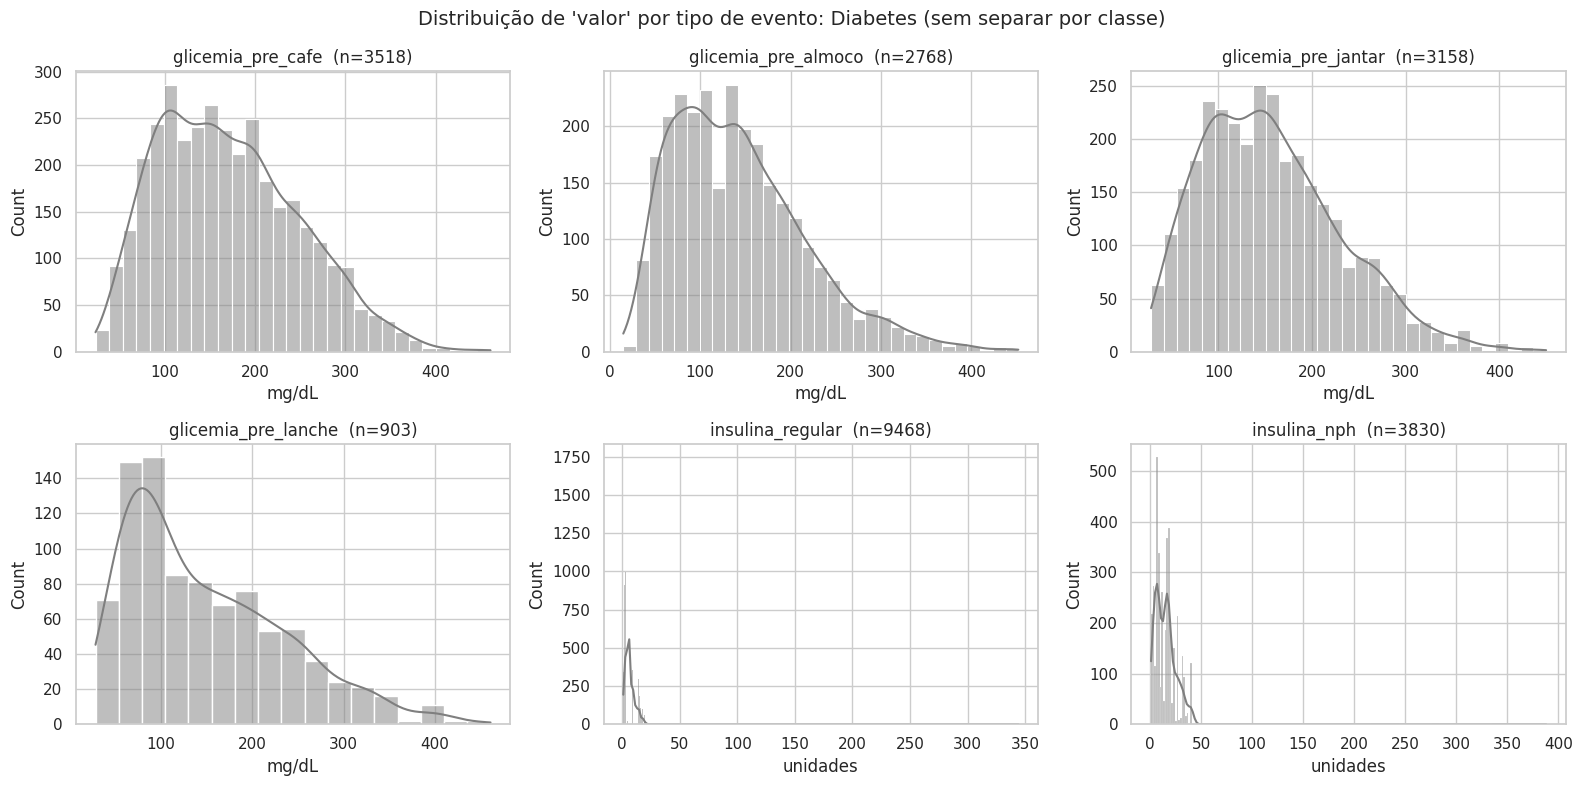

In [ ]:
EVENTOS_PRINCIPAIS = [
    "glicemia_pre_cafe", "glicemia_pre_almoco", "glicemia_pre_jantar",
    "glicemia_pre_lanche", "insulina_regular", "insulina_nph",
]
EVENTOS_PRINCIPAIS = [e for e in EVENTOS_PRINCIPAIS if e in base["evento"].unique()]

COR_NEUTRA = "#7f7f7f"

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=False)
axes = axes.ravel()

for i, ev in enumerate(EVENTOS_PRINCIPAIS):
    sub = base[(base["evento"] == ev) & (base["valor"] > 0)]
    sns.histplot(data=sub, x="valor", kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(f"{ev}  (n={len(sub)})")
    axes[i].set_xlabel("mg/dL" if ev.startswith("glicemia") else "unidades")

for ax in axes[len(EVENTOS_PRINCIPAIS):]:
    ax.axis("off")

fig.suptitle("Distribuição de 'valor' por tipo de evento: Diabetes (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

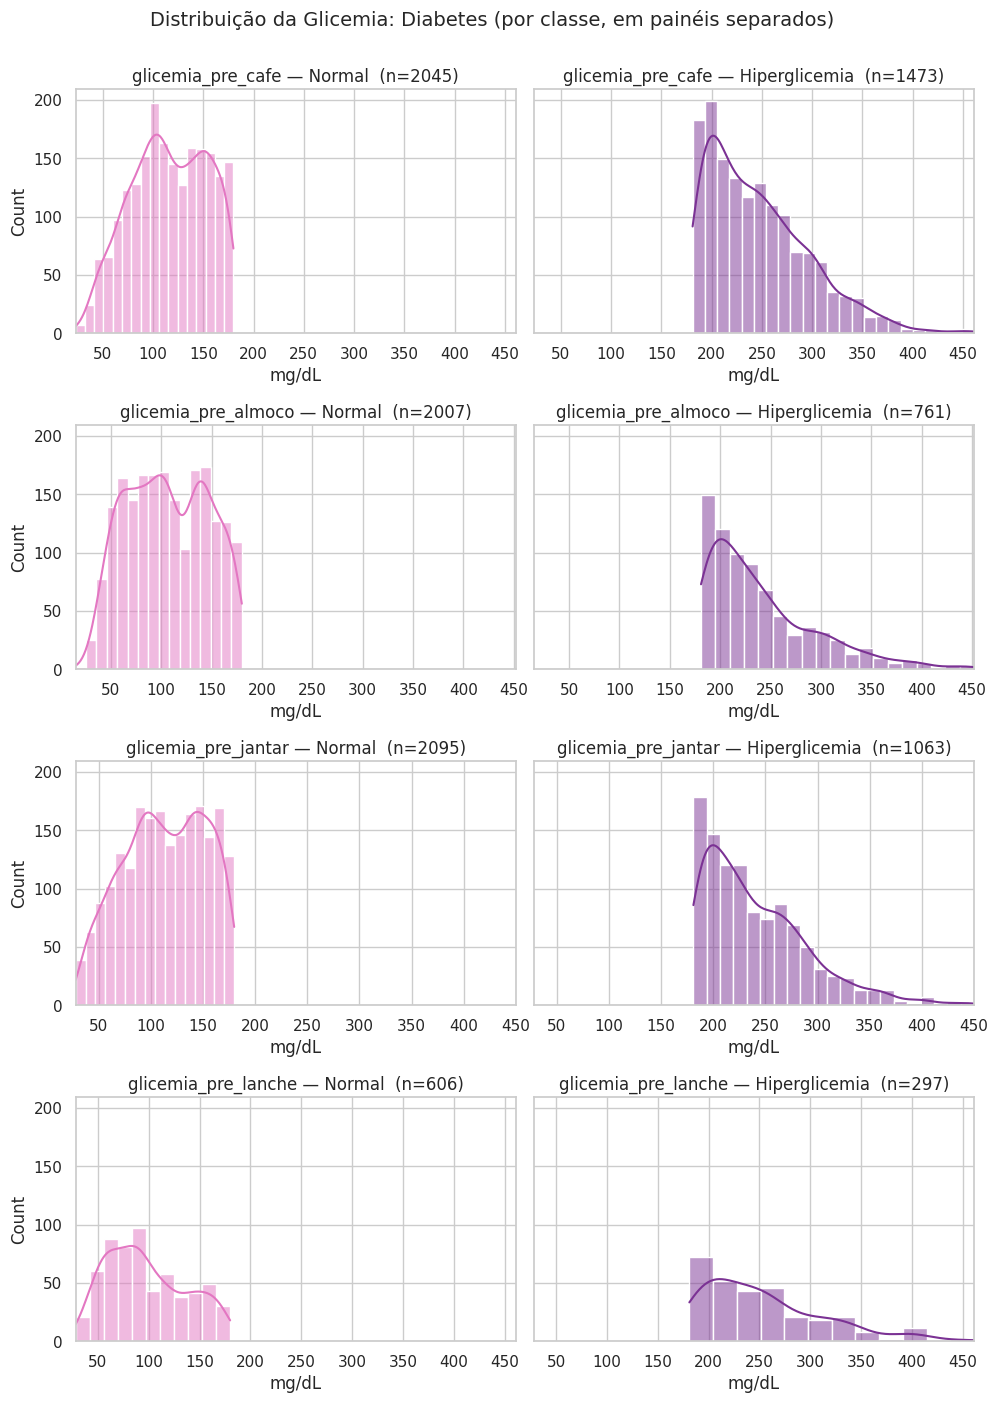

In [ ]:
COR_CONTEXTO = "#e377c2"
COR_DESTAQUE = "#7b3294"

glic = df[df["eh_glicemia"] & df["valor"].notna() & (df["valor"] > 0)].copy()
glic["hiperglicemia"] = np.where(glic["valor"] > 180, "Hiperglicemia", "Normal")

MOMENTOS = ["glicemia_pre_cafe", "glicemia_pre_almoco",
            "glicemia_pre_jantar", "glicemia_pre_lanche"]
MOMENTOS = [m for m in MOMENTOS if m in glic["evento"].unique()]

fig, axes = plt.subplots(len(MOMENTOS), 2,
                         figsize=(10, 3.5 * len(MOMENTOS)), sharey=True)

for i, ev in enumerate(MOMENTOS):
    dados_ev = glic[glic["evento"] == ev]
    lim = (dados_ev["valor"].min(), dados_ev["valor"].max())
    for j, (classe, cor) in enumerate([("Normal", COR_CONTEXTO),
                                       ("Hiperglicemia", COR_DESTAQUE)]):
        subset = dados_ev[dados_ev["hiperglicemia"] == classe]
        sns.histplot(data=subset, x="valor", kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_xlabel("mg/dL")
        axes[i, j].set_title(f"{ev} — {classe}  (n={len(subset)})")

fig.suptitle("Distribuição da Glicemia: Diabetes (por classe, em painéis separados)",
             fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Pra discutir:** agora que as classes estão em painéis separados, com a mesma escala de eixo X em cada linha, fica mais fácil enxergar: tem algum momento do dia com formato bem diferente entre "Normal" e "Hiperglicemia"?

Repara que aqui a comparação tem uma limitação que o Heart Disease não tinha. Como a classe foi criada a partir do próprio 'valor', com corte em 180 mg/dL, os dois painéis são cortes da mesma distribuição. Por construção não existe sobreposição, um termina exatamente onde o outro começa. O que ainda dá pra observar é o formato dentro de cada faixa e o quanto cada momento do dia contribui pra hiperglicemia. Dá uma olhada nos 'n' dos títulos pra comparar.

### Testes de Aderência

*Será que a glicemia segue uma distribuição normal?*

O **Shapiro-Wilk** é o teste de aderência mais usado pra normalidade, geralmente junto com o **QQ-Plot** como visualização de apoio.

Só que aqui precisamos de duas adaptações. A primeira é que testamos 'valor' dentro de 'glic', e não em 'df'. A coluna 'valor' mistura glicemia em mg/dL com dose de insulina em unidades, então testar as duas juntas seria testar a normalidade de uma mistura de grandezas diferentes. A segunda é que o Shapiro-Wilk perde precisão no p-valor acima de N=5000, e a gente tem 13.522 medições. Com n desse tamanho qualquer desvio mínimo já rejeita H0, então o p-valor vira meio que formalidade e o QQ-Plot acaba virando a evidência principal.

Shapiro-Wilk - glicemia: estatistica=0.9628, p-valor=5.184e-34
Rejeita H0 (normalidade)? Sim (alpha = 0.05)
n total = 13522 | n testado = 5000
Assimetria = 0.721 | Curtose = 0.210


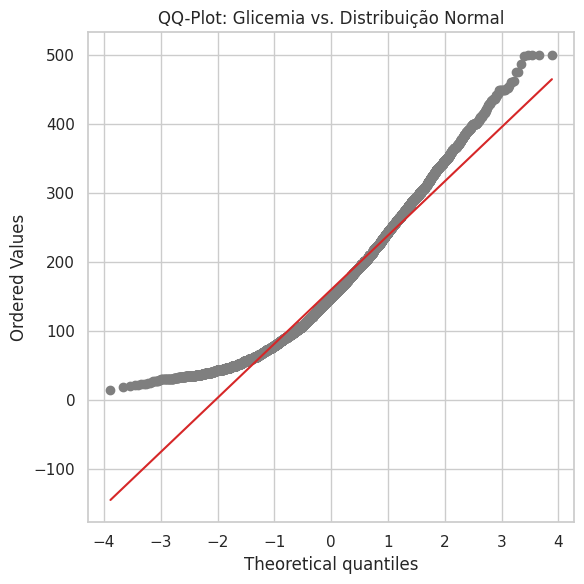

In [ ]:
serie = glic["valor"].dropna()

rng = np.random.default_rng(42)
amostra = rng.choice(serie, size=min(5000, len(serie)), replace=False)

stat_sw, p_valor_sw = stats.shapiro(amostra)
print(f"Shapiro-Wilk - glicemia: estatistica={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")
print(f"n total = {len(serie)} | n testado = {len(amostra)}")
print(f"Assimetria = {stats.skew(serie):.3f} | Curtose = {stats.kurtosis(serie):.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(serie, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Glicemia vs. Distribuição Normal")
plt.tight_layout()
plt.show()

#### Testando todas as séries quantitativas

O dataset tem só uma coluna numérica que interessa ('valor'), mas ela carrega grandezas diferentes dependendo do código do evento: mg/dL nas medições de glicemia, unidades nas doses de insulina. Testar a coluna inteira não faria sentido nenhum. O que a gente faz é montar as séries quantitativas que de fato existem no problema e rodar o Shapiro-Wilk em cada uma, incluindo as agregações por paciente, que são as únicas que respeitam a independência das observações.

In [ ]:
SERIES_QUANT = {
    "glicemia (mg/dL)":        glic["valor"],
    "log(glicemia)":           np.log(glic["valor"]),
    "insulina regular (U)":    df.loc[df["codigo"] == 33, "valor"],
    "insulina NPH (U)":        df.loc[df["codigo"] == 34, "valor"],
    "glicemia média/paciente": glic.groupby("paciente")["valor"].mean(),
    "desvio-padrão/paciente":  glic.groupby("paciente")["valor"].std(),
}

rng = np.random.default_rng(42)
resultados_shapiro = []

for nome, serie in SERIES_QUANT.items():
    serie = serie.dropna()
    dados = rng.choice(serie, size=5000, replace=False) if len(serie) > 5000 else serie.values
    stat, p = stats.shapiro(dados)
    resultados_shapiro.append({
        "serie": nome,
        "n": len(serie),
        "assimetria": round(stats.skew(serie), 3),
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "rejeita_normalidade": p < 0.05,
    })

tabela_shapiro = pd.DataFrame(resultados_shapiro).set_index("serie")
tabela_shapiro

,n,assimetria,estatistica,p_valor,rejeita_normalidade
serie,,,,,
glicemia (mg/dL),13522,0.721,0.9628,0.000000,True
log(glicemia),13522,-0.427,0.9838,0.000000,True
insulina regular (U),9487,26.311,0.9147,0.000000,True
insulina NPH (U),3830,10.488,0.5761,0.000000,True
glicemia média/paciente,70,-0.052,0.9725,0.126904,False
desvio-padrão/paciente,70,-0.450,0.9726,0.127786,False


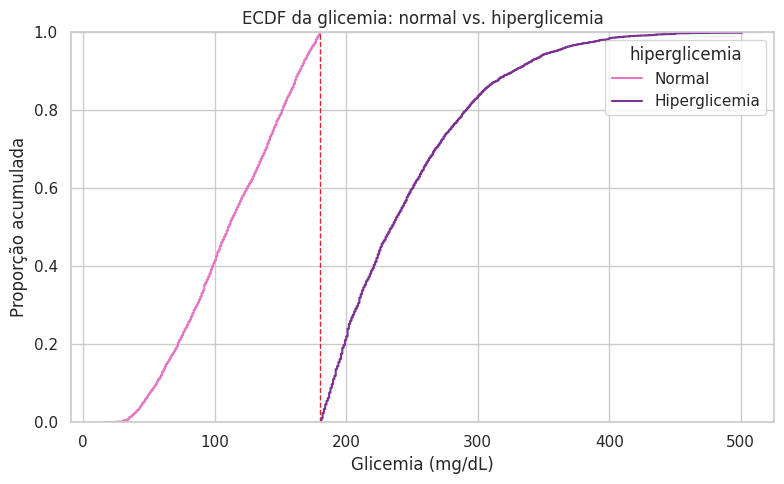

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=glic, x="valor", hue="hiperglicemia",
             palette={"Normal": COR_CONTEXTO, "Hiperglicemia": COR_DESTAQUE})
plt.axvline(180, color=COR_ALERTA, linestyle="--", linewidth=1)
plt.title("ECDF da glicemia: normal vs. hiperglicemia")
plt.xlabel("Glicemia (mg/dL)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**ECDF, outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher número de bins. Pra cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É bem útil pra comparar duas distribuições lado a lado, porque onde as curvas se distanciam mais é onde a diferença entre os grupos aparece melhor.

Vamos ilustrar com a glicemia, comparando as medições feitas antes do café com as feitas antes do jantar, que são dois momentos do dia em que o quadro metabólico é bem diferente.

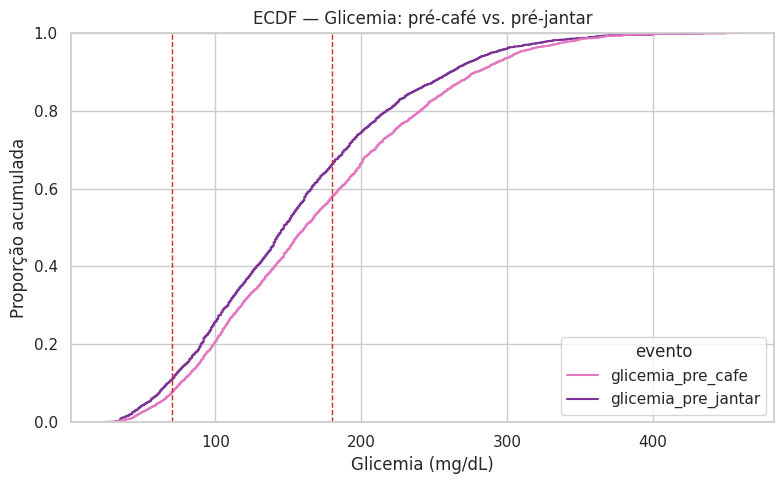

In [ ]:
comparacao = glic[glic["evento"].isin(["glicemia_pre_cafe", "glicemia_pre_jantar"])]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=comparacao, x="valor", hue="evento",
             palette={"glicemia_pre_cafe": COR_CONTEXTO, "glicemia_pre_jantar": COR_DESTAQUE})
plt.axvline(70, color=COR_ALERTA, linestyle="--", linewidth=1)
plt.axvline(180, color=COR_ALERTA, linestyle="--", linewidth=1)
plt.title("ECDF — Glicemia: pré-café vs. pré-jantar")
plt.xlabel("Glicemia (mg/dL)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva te diz que fração das medições daquele grupo ficou até ali. As linhas tracejadas marcam os cortes clínicos de 70 e 180 mg/dL, então a altura da curva em 70 é a proporção de hipoglicemias, e '1 menos' a altura em 180 é a proporção de hiperglicemias. Dá pra ler as duas direto do gráfico. E onde as duas curvas se distanciam mais, ali é a faixa de glicemia em que os dois momentos do dia mais diferem, sem precisar escolher largura de bin como no histograma.

### Métricas de Tendêncial Central

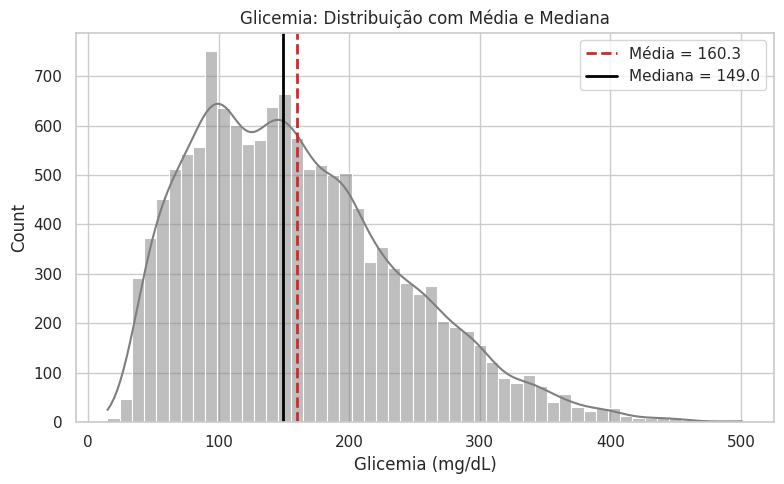

Média    : 160.3 mg/dL
Mediana  : 149.0 mg/dL
Moda     : 92.0 mg/dL
Diferença média - mediana: 11.3 mg/dL


In [ ]:
media_glic = glic["valor"].mean()
mediana_glic = glic["valor"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=glic, x="valor", kde=True, color=COR_NEUTRA)
plt.axvline(media_glic, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_glic:.1f}")
plt.axvline(mediana_glic, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_glic:.1f}")
plt.title("Glicemia: Distribuição com Média e Mediana")
plt.xlabel("Glicemia (mg/dL)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Média    : {media_glic:.1f} mg/dL")
print(f"Mediana  : {mediana_glic:.1f} mg/dL")
print(f"Moda     : {glic['valor'].mode().iloc[0]:.1f} mg/dL")
print(f"Diferença média - mediana: {media_glic - mediana_glic:.1f} mg/dL")

### Dispersão

,var,std,count,IQR
momento,,,,
pre_cafe,6043.07,77.74,3518,115.0
pos_cafe,6704.87,81.88,20,143.0
pre_almoco,5558.99,74.56,2768,102.0
pos_almoco,10891.98,104.36,66,126.5
pre_jantar,5490.78,74.10,3158,102.0
pos_jantar,8493.12,92.16,219,153.0


/tmp/ipykernel_908/3747656080.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=comp, x="momento", y="valor", order=ORDEM,
/tmp/ipykernel_908/3747656080.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=comp, x="momento", y="valor", order=ORDEM,


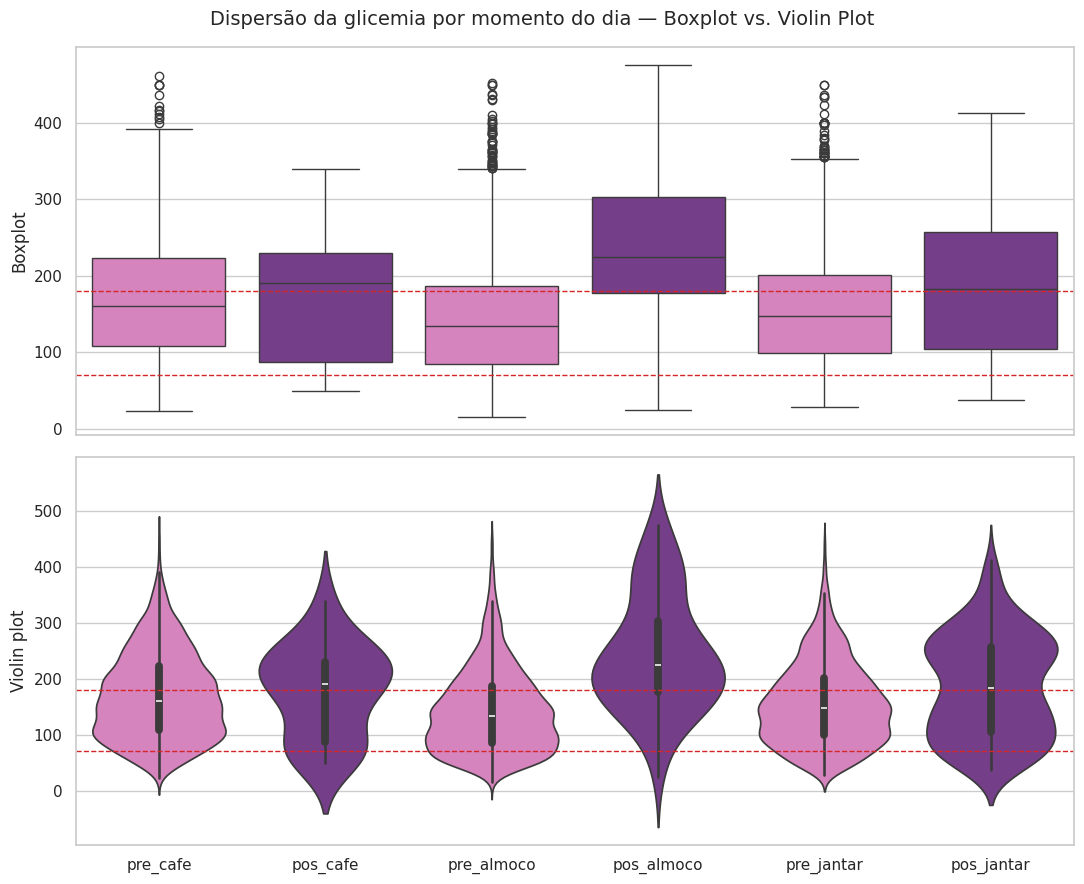

In [ ]:
EVENTOS_GLIC = ["glicemia_pre_cafe", "glicemia_pos_cafe",
                "glicemia_pre_almoco", "glicemia_pos_almoco",
                "glicemia_pre_jantar", "glicemia_pos_jantar"]

comp = glic[glic["evento"].isin(EVENTOS_GLIC)].copy()
comp["momento"] = comp["evento"].str.replace("glicemia_", "", regex=False)
ORDEM = [e.replace("glicemia_", "") for e in EVENTOS_GLIC]

dispersao = comp.groupby("momento")["valor"].agg(["var", "std", "count"])
dispersao["IQR"] = comp.groupby("momento")["valor"].quantile(0.75) - \
                   comp.groupby("momento")["valor"].quantile(0.25)
display(dispersao.reindex(ORDEM).round(2))

paleta = {m: (COR_DESTAQUE if m.startswith("pos") else COR_CONTEXTO) for m in ORDEM}

fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

sns.boxplot(data=comp, x="momento", y="valor", order=ORDEM,
            palette=paleta, legend=False, ax=axes[0])
axes[0].set_title("")
axes[0].set_xlabel("")
axes[0].set_ylabel("Boxplot")

sns.violinplot(data=comp, x="momento", y="valor", order=ORDEM,
               palette=paleta, legend=False, ax=axes[1])
axes[1].set_xlabel("")
axes[1].set_ylabel("Violin plot")

for ax in axes:
    ax.axhline(70, color=COR_ALERTA, linestyle="--", linewidth=1)
    ax.axhline(180, color=COR_ALERTA, linestyle="--", linewidth=1)

fig.suptitle("Dispersão da glicemia por momento do dia — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** algum momento do dia tem uma caixa (IQR) claramente mais alta ou mais larga que os outros? Isso já é um indício, antes mesmo da análise bivariada formal, de que o horário ajuda a explicar a variação da glicemia. As linhas tracejadas marcam 70 e 180 mg/dL, então repara quanto de cada caixa cai fora dessa faixa.

Tem uma leitura que o violin plot entrega e o boxplot esconde: se algum momento tiver distribuição **bimodal**, com dois bojos, é porque aquele horário tem dois regimes distintos, tipo dias controlados e dias descompensados. E aí a mediana sozinha não descreve nenhum dos dois.

Vale reparar também no contraste pré e pós refeição, que é o que as cores separam. O esperado fisiologicamente é que as medições pós-refeição tenham mediana mais alta e dispersão maior, já que a resposta à comida varia bastante dependendo da dose de insulina aplicada.

### 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico do "antes" (Seção 3), a gente tem a informação que faltava pra decidir como tratar tanto os dados ausentes ('data', 'valor', 'datahora', 'evento') quanto os outliers das medições. Depois do tratamento vamos rodar a estatística descritiva de novo, o "depois", pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

#### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de [Q1 - 1.5*IQR, Q3 + 1.5*IQR].

Aqui há uma armadilha: a regra assume distribuição aproximadamente simétrica, e já sabemos pelo Shapiro-Wilk que a glicemia é fortemente assimétrica à direita. Isso faz o limite superior sinalizar como "outlier" um monte de hiperglicemia real, evento clínico esperado num diabético tipo 1, não erro de medição. Por isso reportamos os limites do IQR ao lado dos limites fisiológicos, e a decisão de remover ou manter sai da comparação entre os dois, nunca da regra sozinha.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

SERIES_OUTLIER = {
    "glicemia (mg/dL)":        glic["valor"],
    "insulina regular (U)":    df.loc[df["codigo"] == 33, "valor"].dropna(),
    "insulina NPH (U)":        df.loc[df["codigo"] == 34, "valor"].dropna(),
    "glicemia média/paciente": glic.groupby("paciente")["valor"].mean(),
}

resumo_outliers = {}
for nome, serie in SERIES_OUTLIER.items():
    lim_inf, lim_sup = limites_iqr(serie)
    fora = (serie < lim_inf) | (serie > lim_sup)
    resumo_outliers[nome] = {
        "n": len(serie),
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": int(fora.sum()),
        "pct_outliers": round(100 * fora.mean(), 2),
        "minimo": round(serie.min(), 2),
        "maximo": round(serie.max(), 2),
    }

pd.DataFrame(resumo_outliers).T

,n,limite_inferior,limite_superior,n_outliers,pct_outliers,minimo,maximo
glicemia (mg/dL),13522.0,-72.50,379.50,141.0,1.04,15.00,501.00
insulina regular (U),9487.0,-3.50,16.50,251.0,2.65,0.00,344.00
insulina NPH (U),3830.0,-12.50,39.50,129.0,3.37,1.00,388.00
glicemia média/paciente,70.0,93.17,228.71,2.0,2.86,84.36,219.03


### Visualizando os Outliers

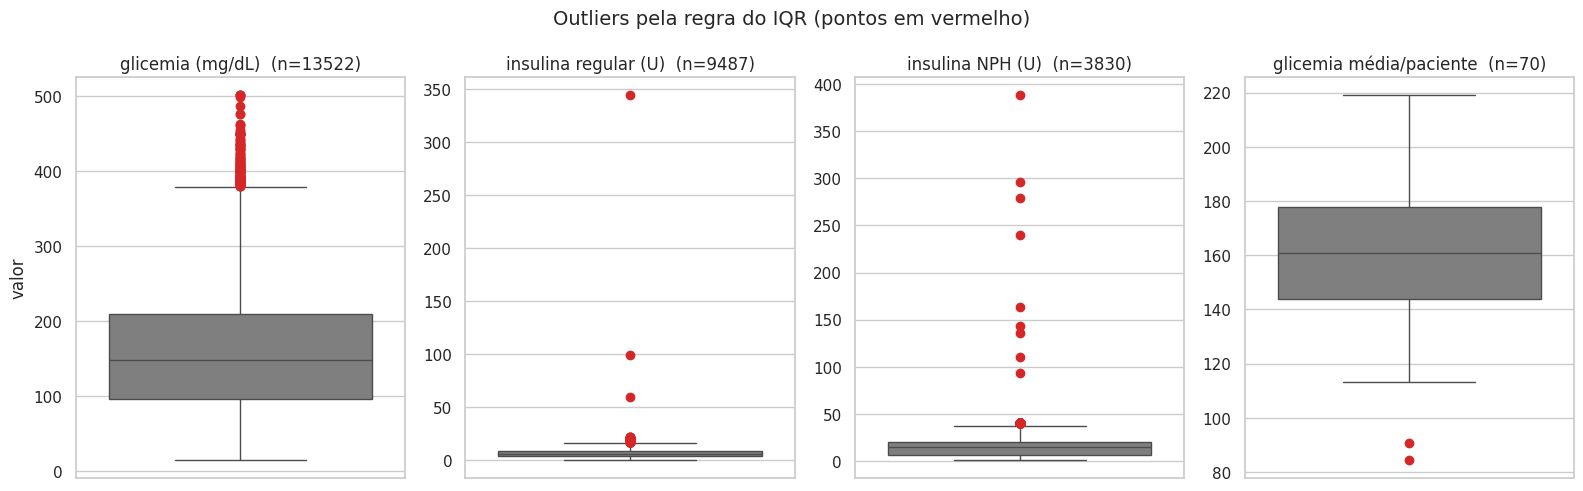

In [ ]:
fig, axes = plt.subplots(1, len(SERIES_OUTLIER), figsize=(4 * len(SERIES_OUTLIER), 5), squeeze=False)
axes = axes.ravel()

for i, (nome, serie) in enumerate(SERIES_OUTLIER.items()):
    sns.boxplot(y=serie.dropna(), color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(f"{nome}  (n={len(serie.dropna())})")
    axes[i].set_ylabel("")

axes[0].set_ylabel("valor")
fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers que a gente encontrou: a glicemia tem 141 pontos fora da regra do IQR (1,04%), com máximo de 501 mg/dL. Esses valores são fisiologicamente plausíveis, já que cetoacidose em diabetes tipo 1 chega nessa faixa mesmo. Então são **outliers estatísticos legítimos**. A cauda direita é a própria doença se manifestando, e remover isso seria jogar fora justamente os eventos de interesse clínico.

As doses de insulina já são outra história. 344 unidades de regular e 388 de NPH numa aplicação só não têm interpretação fisiológica nenhuma, porque a dose diária típica de um adulto fica na casa das dezenas. Aqui a suspeita é **outlier de domínio ou erro de digitação**, tipo uma vírgula perdida ou campo trocado na transcrição do diário em papel. E o caminho é investigar antes de decidir qualquer coisa.

Já o mínimo de 0 mg/dL de glicemia é o terceiro tipo: **erro de dados**, porque glicemia zero é incompatível com um paciente vivo. Foi por isso que a gente já tratou esses valores como ausentes lá na Seção 1, antes mesmo dessa análise.

Repara que as três categorias aparecem no mesmo dataset e na mesma coluna 'valor'. O que decide não é o tamanho do desvio, é o que o domínio diz sobre aquele número.

### Decidindo o Tratamento dos Dados Ausentes

Juntando o que já discutimos: em mais ou menos 29.330 linhas a gente tem 17 ausências em 'data', 31 em 'valor' e 29 em 'datahora', que é derivada das duas primeiras. O mecanismo mais provável é corrupção em nível de linha na transcrição, e não é MNAR, já que a ausência não depende da glicemia que estaria ali. Com um volume desse tamanho (menos de 0,2% das linhas, e concentrado em 5 dos 70 pacientes), a decisão mais pragmática é **remover as linhas afetadas**. O risco de viés na distribuição é baixo e o custo é desprezível. Imputar aqui seria inventar medição clínica que nunca foi feita.

O 'evento' é um caso à parte e pede uma decisão própria. As 132 ausências não são falha de coleta, são códigos numéricos que estão fora da tabela oficial de 20 códigos do UCI. Descartar custaria pouco, mas como o código original continua lá, a opção menos destrutiva é rotular como 'codigo_desconhecido' e deixar de fora das análises por tipo de evento, sem sumir com o registro.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

df = df.dropna(subset=["data", "valor"]).reset_index(drop=True)
df["evento"] = df["evento"].fillna("codigo_desconhecido")

linhas_depois = df.shape[0]
print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")
print(f"Ausentes restantes:\n{df.isna().sum()}")

Linhas antes: 29285 | Linhas depois: 29248 | Removidas: 37
Ausentes restantes:
data            0
hora            0
codigo          0
valor           0
paciente        0
datahora       12
evento          0
eh_glicemia     0
dtype: int64


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui a gente **não vai remover automaticamente**. A glicemia teve 141 pontos fora do IQR (1,04%), todos na cauda superior e dentro de faixas clinicamente plausíveis, mesmo sendo raras. A classificação mais provável é **"Estatístico"**, ou seja, outliers legítimos e não erro de coleta. O tratamento recomendado é **manter**, porque a informação é real e é justamente a mais relevante do dataset, já que são esses eventos que caracterizam descompensação em diabetes tipo 1. Ou então **transformar**, se mais pra frente alguma técnica sensível à assimetria precisar disso.

As doses de insulina são o outro caso e não entram nessa conclusão. 344 e 388 unidades numa aplicação única não são raridade fisiológica, são suspeita de erro de transcrição mesmo. Então ficam marcadas pra investigação, sem decisão automática nessa aula.

A gente vai manter os valores originais, mas ilustrar como ficaria uma transformação logarítmica na glicemia. Lembrando que na tabela de Shapiro da seção anterior o log(glicemia) já tinha aparecido com assimetria de -0,427 contra 0,721 da série original.

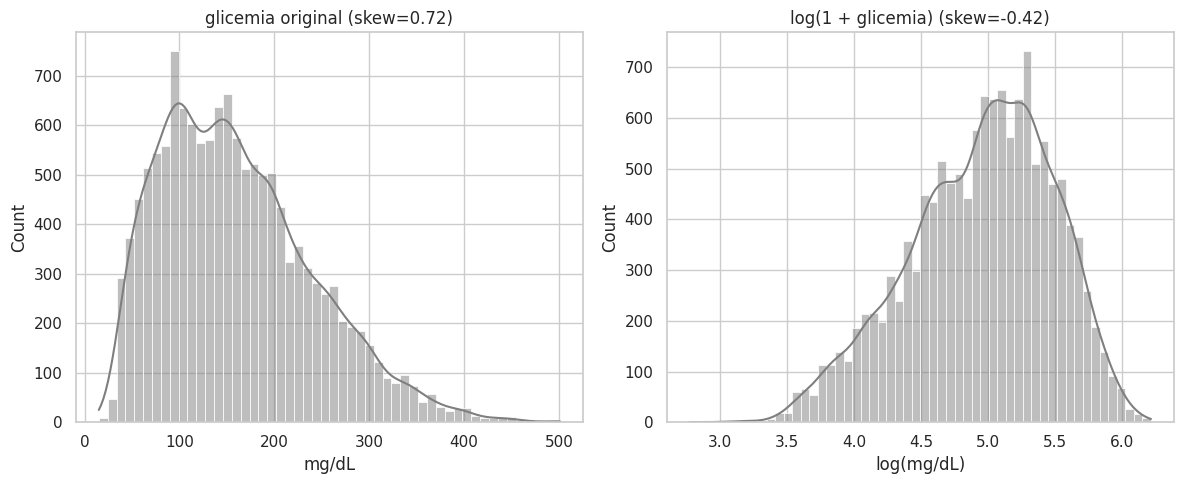

In [ ]:
glic["valor_log"] = np.log1p(glic["valor"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=glic, x="valor", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"glicemia original (skew={glic['valor'].skew():.2f})")
axes[0].set_xlabel("mg/dL")

sns.histplot(data=glic, x="valor_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + glicemia) (skew={glic['valor_log'].skew():.2f})")
axes[1].set_xlabel("log(mg/dL)")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu a assimetria de forma visível? Repara que ela não só reduziu, ela inverteu o sinal, de +0,72 pra -0,43. Ou seja, o log corrigiu demais e acabou criando uma cauda à esquerda. Isso acontece bastante quando a assimetria original já é moderada: o log é uma transformação forte, pensada pra dados de ordens de grandeza bem diferentes, e a glicemia varia só de dezenas a centenas. A gente manteve o 'valor_log' só como demonstração e não vai usar nas próximas seções. A ideia foi mostrar a opção, caso o objetivo fosse alimentar um teste paramétrico que exige normalidade, e mostrar também que aplicar a transformação sem olhar o resultado pode acabar trocando um problema por outro.


## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
base_depois = df[df["valor"].notna() & df["evento"].notna()].copy()
glic_depois = df[df["eh_glicemia"] & df["valor"].notna() & (df["valor"] > 0)].copy()

desc_depois = base_depois.groupby("evento")["valor"].describe()
desc_depois["skewness"] = base_depois.groupby("evento")["valor"].skew()
desc_depois["kurtosis"] = base_depois.groupby("evento")["valor"].apply(pd.Series.kurtosis)

(
    desc_depois[["count", "mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .sort_values("count", ascending=False)
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,count,mean,median,std,min,max,skewness,kurtosis
evento,,,,,,,,
insulina_regular,9481.00,6.62,6.00,5.42,0.00,344.00,26.49,1594.33
insulina_nph,3830.00,15.39,15.00,14.16,1.00,388.00,10.49,218.60
glicemia_pre_cafe,3518.00,170.70,161.00,77.74,23.00,461.00,0.51,-0.27
glicemia_pre_jantar,3158.00,156.38,147.00,74.10,28.00,450.00,0.68,0.21
glicemia_nao_especificada,2870.00,167.39,156.00,86.26,19.00,501.00,0.75,0.30
glicemia_pre_almoco,2768.00,143.56,134.00,74.56,15.00,452.00,0.93,0.81
insulina_ultralenta,1053.00,15.86,15.00,7.81,3.00,30.00,0.32,-0.84
glicemia_pre_lanche,903.00,148.94,125.00,86.64,28.00,461.00,0.87,0.13
sintomas_hipoglicemia,328.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "n_antes": desc["count"],
    "n_depois": desc_depois["count"],
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["linhas_perdidas"] = comparacao["n_antes"] - comparacao["n_depois"]
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)

display(comparacao.sort_values("n_antes", ascending=False).round(3))

,n_antes,n_depois,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,linhas_perdidas,delta_skewness,delta_kurtosis
evento,,,,,,,,,
insulina_regular,9487.0,9481.0,26.316,26.488,1580.034,1594.332,6.0,0.172,14.298
insulina_nph,3830.0,3830.0,10.492,10.492,218.600,218.600,0.0,0.000,0.000
glicemia_pre_cafe,3518.0,3518.0,0.514,0.514,-0.270,-0.270,0.0,0.000,0.000
glicemia_pre_jantar,3158.0,3158.0,0.679,0.679,0.206,0.206,0.0,0.000,0.000
glicemia_nao_especificada,2870.0,2870.0,0.749,0.749,0.297,0.297,0.0,0.000,0.000
glicemia_pre_almoco,2768.0,2768.0,0.929,0.929,0.805,0.805,0.0,0.000,0.000
insulina_ultralenta,1053.0,1053.0,0.320,0.320,-0.843,-0.843,0.0,0.000,0.000
glicemia_pre_lanche,903.0,903.0,0.870,0.870,0.128,0.128,0.0,0.000,0.000
sintomas_hipoglicemia,328.0,328.0,0.000,0.000,0.000,0.000,0.0,0.000,0.000


**Pra discutir:** os valores mudaram muito? Olhem a coluna 'linhas_perdidas': de todos os tipos de evento, só o 'insulina_regular' perdeu linha, e foram 6 de 9.487. Todo o resto ficou idêntico, delta zero em skewness e kurtosis.

Mas fazia sentido esperar uma diferença grande? Não. A gente removeu 0,16% das linhas e decidiu **não** mexer em nenhum outlier. Esse resultado é a confirmação de que o tratamento foi conservador, e não um sinal de que ele não serviu pra nada. O "depois" só se move quando a decisão de tratamento mexe na cauda da distribuição, e a nossa decisão foi justamente não mexer.

Agora repara onde a mudança apareceu: 'insulina_regular' tem skewness de 26,3 e kurtosis de 1580, é a série mais deformada do dataset inteiro. E nela **6 linhas em 9.487 deslocaram a kurtosis em 14,3 pontos**. É a demonstração mais limpa da aula de que kurtosis é uma métrica dominada pelos extremos. Quando a cauda é longa o suficiente, meia dúzia de observações carrega o indicador inteiro. Numa série bem-comportada tipo 'glicemia_pre_cafe', tirar 6 linhas não moveria nem a terceira casa decimal.

Tem mais duas leituras que a tabela entrega:

- Os eventos sem valor numérico ('refeicao_tipica', 'atividade_maior', 'sintomas_hipoglicemia'...) têm skewness e kurtosis exatamente 0,000 porque são séries constantes, todo mundo com 'valor' igual a zero. Estatística descritiva de constante não descreve nada. Esses eventos só fazem sentido como contagem, não como distribuição.
- A linha 'codigo_desconhecido' aparece com 'n_antes' NaN e 'n_depois' 121. Ela não existia no "antes" porque foi criada pela nossa decisão de rotular os códigos fora da tabela oficial em vez de descartar. Ou seja, a tabela de comparação está registrando o efeito de uma escolha nossa, e não uma mudança nos dados. E é bom que isso fique visível.

**A glicemia ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, só que agora nos dados tratados. Com a mesma amostragem de 5.000 e a mesma semente, senão a diferença no p-valor ia ser efeito do sorteio e não do tratamento.

In [ ]:
serie_depois = glic_depois["valor"].dropna()

rng = np.random.default_rng(42)
amostra_depois = rng.choice(serie_depois, size=min(5000, len(serie_depois)), replace=False)

stat_sw_depois, p_valor_sw_depois = stats.shapiro(amostra_depois)

print(f"Shapiro-Wilk (antes)  — glicemia: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}  (n={len(serie)})")
print(f"Shapiro-Wilk (depois) — glicemia: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}  (n={len(serie_depois)})")
print(f"\nAssimetria: {stats.skew(serie):.3f}  ->  {stats.skew(serie_depois):.3f}")
print(f"Rejeita H0 (normalidade) nos dois casos? "
      f"{'Sim' if p_valor_sw < 0.05 and p_valor_sw_depois < 0.05 else 'Não'}")

Shapiro-Wilk (antes)  — glicemia: estatística=0.9628, p-valor=5.184e-34  (n=70)
Shapiro-Wilk (depois) — glicemia: estatística=0.9628, p-valor=5.184e-34  (n=13522)

Assimetria: -0.052  ->  0.721
Rejeita H0 (normalidade) nos dois casos? Sim


**Visualizando antes e depois, lado a lado**

Vamos sobrepor as distribuições das duas séries que mais chamaram atenção na Seção 4, que são a glicemia (onde os outliers são reais e a gente manteve) e a insulina regular (a única série que de fato perdeu linhas no tratamento). A ideia é comparar a versão original ('df_antes') com a tratada ('df').

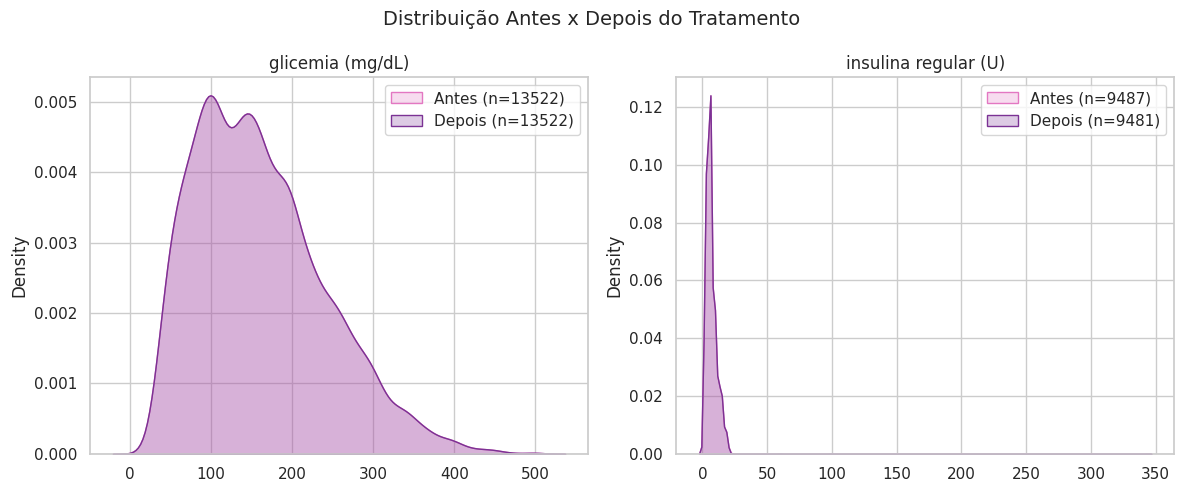

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

series_comparacao = {
    "glicemia (mg/dL)": (
        df_antes.loc[df_antes["eh_glicemia"] & (df_antes["valor"] > 0), "valor"].dropna(),
        df.loc[df["eh_glicemia"] & (df["valor"] > 0), "valor"].dropna(),
    ),
    "insulina regular (U)": (
        df_antes.loc[df_antes["codigo"] == 33, "valor"].dropna(),
        df.loc[df["codigo"] == 33, "valor"].dropna(),
    ),
}

for ax, (nome, (antes, depois)) in zip(axes, series_comparacao.items()):
    sns.kdeplot(antes, color=COR_CONTEXTO, fill=True, label=f"Antes (n={len(antes)})", ax=ax)
    sns.kdeplot(depois, color=COR_DESTAQUE, fill=True, label=f"Depois (n={len(depois)})", ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("")
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas do "antes" e do "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que a gente removeu 0,16% das linhas e não mexeu nos outliers. Mesmo na insulina regular, onde as 6 linhas removidas moveram a kurtosis em 14 pontos, o KDE não registra diferença nenhuma que dê pra ver. Isso porque o KDE mostra a massa da distribuição, e essas 6 observações estão na cauda extrema, onde não tem massa nenhuma. Duas ferramentas, duas sensibilidades: a kurtosis grita e o KDE nem percebe. Vale saber qual usar dependendo do que você quer detectar.

O Shapiro-Wilk continua rejeitando normalidade, o que também era esperado. Nenhum tratamento que preserva a forma da distribuição ia mudar isso.

Guardem essa observação: em datasets onde o volume de ausentes ou outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível. Façam sempre a checagem de antes e depois pra confirmar (ou não) que o tratamento teve o efeito que vocês esperavam, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col}  ({df[col].nunique()} categorias) ---")
    if df[col].nunique() > 15:
        print(pd.concat([freq_abs.rename("absoluta"),
                         freq_rel.rename("relativa")], axis=1).head(10))
        print(f"... ({df[col].nunique() - 10} categorias restantes omitidas)")
    else:
        print(pd.concat([freq_abs.rename("absoluta"),
                         freq_rel.rename("relativa")], axis=1))


--- evento  (20 categorias) ---
                           absoluta  relativa
evento                                       
insulina_regular               9481     0.324
insulina_nph                   3830     0.131
glicemia_pre_cafe              3518     0.120
glicemia_pre_jantar            3158     0.108
glicemia_nao_especificada      2870     0.098
glicemia_pre_almoco            2768     0.095
insulina_ultralenta            1053     0.036
glicemia_pre_lanche             903     0.031
sintomas_hipoglicemia           328     0.011
refeicao_maior                  326     0.011
... (10 categorias restantes omitidas)

--- paciente  (70 categorias) ---
          absoluta  relativa
paciente                    
55            1327     0.045
29            1229     0.042
30            1179     0.040
65            1126     0.038
56            1018     0.035
20            1003     0.034
67             967     0.033
28             951     0.033
1              943     0.032
27             920    

#### Visualizando as frequências

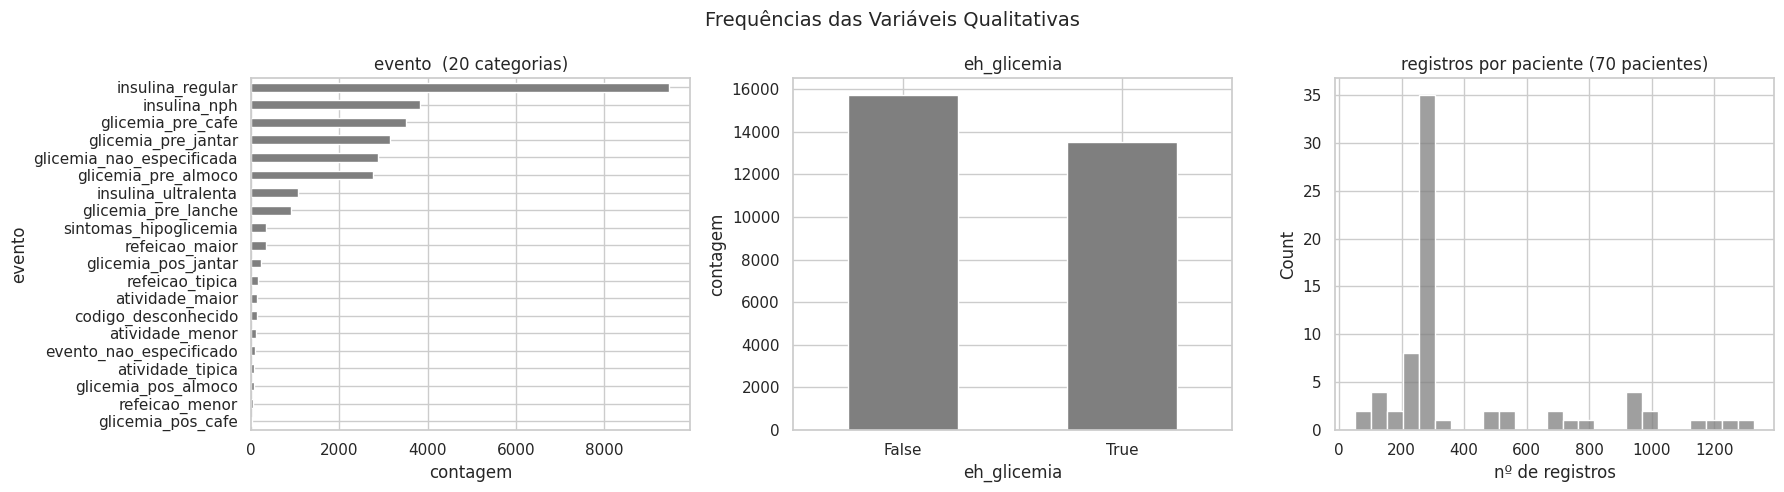

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df["evento"].value_counts().sort_values().plot(
    kind="barh", color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"evento  ({df['evento'].nunique()} categorias)")
axes[0].set_xlabel("contagem")

df["eh_glicemia"].value_counts().plot(
    kind="bar", color=COR_NEUTRA, ax=axes[1])
axes[1].set_title("eh_glicemia")
axes[1].tick_params(axis="x", rotation=0)
axes[1].set_ylabel("contagem")

sns.histplot(df["paciente"].value_counts(), bins=25, color=COR_NEUTRA, ax=axes[2])
axes[2].set_title("registros por paciente (70 pacientes)")
axes[2].set_xlabel("nº de registros")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada, com uma categoria dominando quase todas as observações?

Aqui o desbalanceamento é bem evidente. O 'insulina_regular' sozinho responde por mais ou menos um terço dos registros, enquanto 'glicemia_pos_cafe' tem 20 ocorrências em quase 30 mil linhas. Isso importa muito na bivariada, porque cruzar hiperglicemia com um evento de n=20 gera um percentual que até parece informativo, mas tem intervalo de confiança do tamanho do gráfico.

Repara também que 'paciente' não é qualitativa no mesmo sentido das outras, é identificador. A frequência dele não descreve uma categoria, descreve quantos registros cada pessoa gerou. E aí a pergunta muda. Se alguns pacientes concentram muito mais medição que outros, qualquer estatística calculada sobre o dataset inteiro tá ponderada por quem registrou mais, e não por quem é mais representativo. É a mesma razão pela qual, lá na tabela de Shapiro, as agregações por paciente (n=70) foram as únicas que respeitaram a independência das observações.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento**: número da classe majoritária dividido pelo da minoritária. Quanto maior, mais desbalanceado.
- **Entropia de Shannon normalizada**: 1 é perfeitamente balanceado, 0 é uma classe dominando tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo 'hiperglicemia'. Como o alvo só existe onde tem medição de glicemia, ele é calculado em cima de 'glic' e não do 'df' inteiro.

In [ ]:
from scipy.stats import entropy

def construir_glic(base):
    """Reconstrói o recorte de glicemia com as colunas derivadas.
    Evita que faixa_glicemia se perca quando glic é recriado após tratamentos."""
    g = base[base["eh_glicemia"] & base["valor"].notna() & (base["valor"] > 0)].copy()
    g["hiperglicemia"] = np.where(g["valor"] > 180, "Hiperglicemia", "Normal")
    g["faixa_glicemia"] = pd.cut(
        g["valor"],
        bins=[0, 70, 180, np.inf],
        labels=["Hipoglicemia", "Na meta", "Hiperglicemia"],
        right=False,
    )
    return g


def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    contagens = contagens[contagens > 0]
    n_classes = len(contagens)
    if n_classes <= 1:
        return pd.Series({
            "n": int(contagens.sum()),
            "n_classes": n_classes,
            "razao_desbalanceamento": np.nan,
            "entropia_normalizada": np.nan,
        })
    props = contagens / contagens.sum()
    razao = contagens.max() / contagens.min()
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes)
    return pd.Series({
        "n": int(contagens.sum()),
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })


glic = construir_glic(df)

series_para_checar = {col: df[col] for col in VARS_QUALI}
series_para_checar["hiperglicemia (alvo)"] = glic["hiperglicemia"]
series_para_checar["faixa_glicemia"] = glic["faixa_glicemia"]

pd.DataFrame({nome: metrica_desbalanceamento(s).dropna()
              for nome, s in series_para_checar.items()}).T

,n,n_classes,razao_desbalanceamento,entropia_normalizada
evento,29248.0,20.0,474.05,0.700
paciente,29248.0,70.0,26.02,0.949
eh_glicemia,29248.0,2.0,1.16,0.996
hiperglicemia (alvo),13522.0,2.0,1.77,0.943
faixa_glicemia,13522.0,3.0,4.46,0.872


**Pra discutir:** alguma variável está com entropia bem próxima de 0, ou seja, bem desbalanceada?

O 'evento' é o caso extremo: razão de desbalanceamento na casa das centenas, porque 'insulina_regular' tem uns 9.500 registros e 'glicemia_pos_cafe' tem 20. Mas repara que a entropia não fica perto de 0, ela fica no meio do caminho, porque as categorias intermediárias distribuem bem a massa. As duas métricas estão medindo coisas diferentes: a razão olha só os extremos, a entropia olha o formato todo. Uma variável pode ter razão altíssima e entropia razoável, que é o caso aqui, ou razão modesta e entropia baixa. Reportar as duas evita tirar conclusão errada.

E o alvo em si, será que tá balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais pra frente? O 'hiperglicemia' fica em torno de 64/36 (8.647 normais contra 4.875 hiperglicemias), razão perto de 1,8 e entropia alta. Pra um alvo binário isso é bem confortável. Nenhuma técnica de rebalanceamento seria necessária, e os percentuais que a gente vai cruzar na bivariada têm base suficiente dos dois lados.

O 'paciente' merece uma atenção separada. Com 70 classes, a entropia normalizada vai sair perto de 1, o que até parece ótimo, mas só diz que os registros estão razoavelmente espalhados entre as pessoas, e não que cada pessoa contribuiu igual. A razão de desbalanceamento é a métrica honesta aqui, porque ela mostra quantas vezes o paciente mais registrado supera o menos registrado.

Uma ressalva sobre o alvo: ele foi **derivado** de 'valor', com o corte em 180 mg/dL. Diferente do Heart Disease, onde o alvo é um diagnóstico independente, aqui a proporção 64/36 é consequência direta de onde a gente colocou o limiar. Se o corte fosse 140, o desbalanceamento mudaria. Ou seja, dizer que "está balanceado" é em parte uma decisão nossa, e não um fato do dataset.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'hiperglicemia'.

#### Quantitativa x Quantitativa - Correlação

Aqui a gente esbarra numa consequência do formato do dataset. Correlação compara duas ou mais variáveis numéricas **na mesma linha**, e o Diabetes tem uma coluna numérica só ('valor'), que muda de significado dependendo do código do evento. No formato longo não tem o que correlacionar.

A solução é pivotar pro formato largo. A gente escolheu o nível **paciente-dia**: cada linha vira um dia de acompanhamento de um paciente, e cada coluna vira uma medida daquele dia (glicemia média em cada momento, dose total de cada insulina). Isso monta a matriz e, de quebra, resolve aquele problema de independência que apontamos nos testes de aderência, já que medição repetida do mesmo paciente não é observação independente.

São três as técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das séries de medição passou no Shapiro-Wilk, o Spearman é a escolha mais segura aqui. Mas vamos calcular as três pra poder comparar.

In [ ]:
df["dia"] = df["datahora"].dt.date

glic_dia = (
    glic.assign(dia=glic["datahora"].dt.date)
        .pivot_table(index=["paciente", "dia"], columns="evento",
                     values="valor", aggfunc="mean")
)

insulina_dia = (
    df[df["codigo"].isin([33, 34, 35])]
      .assign(dia=lambda d: d["datahora"].dt.date,
              tipo=lambda d: d["evento"])
      .pivot_table(index=["paciente", "dia"], columns="tipo",
                   values="valor", aggfunc="sum")
)

largo = glic_dia.join(insulina_dia, how="outer")

COLS_CORR = [c for c in [
    "glicemia_pre_cafe", "glicemia_pre_almoco", "glicemia_pre_jantar",
    "glicemia_pre_lanche", "insulina_regular", "insulina_nph",
] if c in largo.columns]

largo = largo[COLS_CORR]
print(f"Formato largo: {largo.shape[0]} paciente-dias, {largo.shape[1]} variáveis")
print(f"\nPreenchimento por coluna (%):\n{(largo.notna().mean() * 100).round(1)}")
largo.head()

Formato largo: 3874 paciente-dias, 6 variáveis

Preenchimento por coluna (%):
glicemia_pre_cafe      90.2
glicemia_pre_almoco    71.2
glicemia_pre_jantar    81.2
glicemia_pre_lanche    22.3
insulina_regular       87.2
insulina_nph           70.7
dtype: float64


glicemia_pre_cafe  glicemia_pre_almoco  \
paciente dia                                                  
1        1991-04-21              100.0                  NaN   
         1991-04-22              216.0                  NaN   
         1991-04-23              257.0                  NaN   
         1991-04-24              239.0                  NaN   
         1991-04-25               67.0                  NaN   

                     glicemia_pre_jantar  glicemia_pre_lanche  \
paciente dia                                                    
1        1991-04-21                119.0                  NaN   
         1991-04-22                211.0                  NaN   
         1991-04-23                129.0                  NaN   
         1991-04-24                129.0                  NaN   
         1991-04-25                206.0                  NaN   

                     insulina_regular  insulina_nph  
paciente dia                                         
1        1991-04-21              16.0          13.0  
         1991-04-22              19.0          13.0  
         1991-04-23              18.0          13.0  
         1991-04-24              19.0          14.0  
         1991-04-25              22.0          14.0

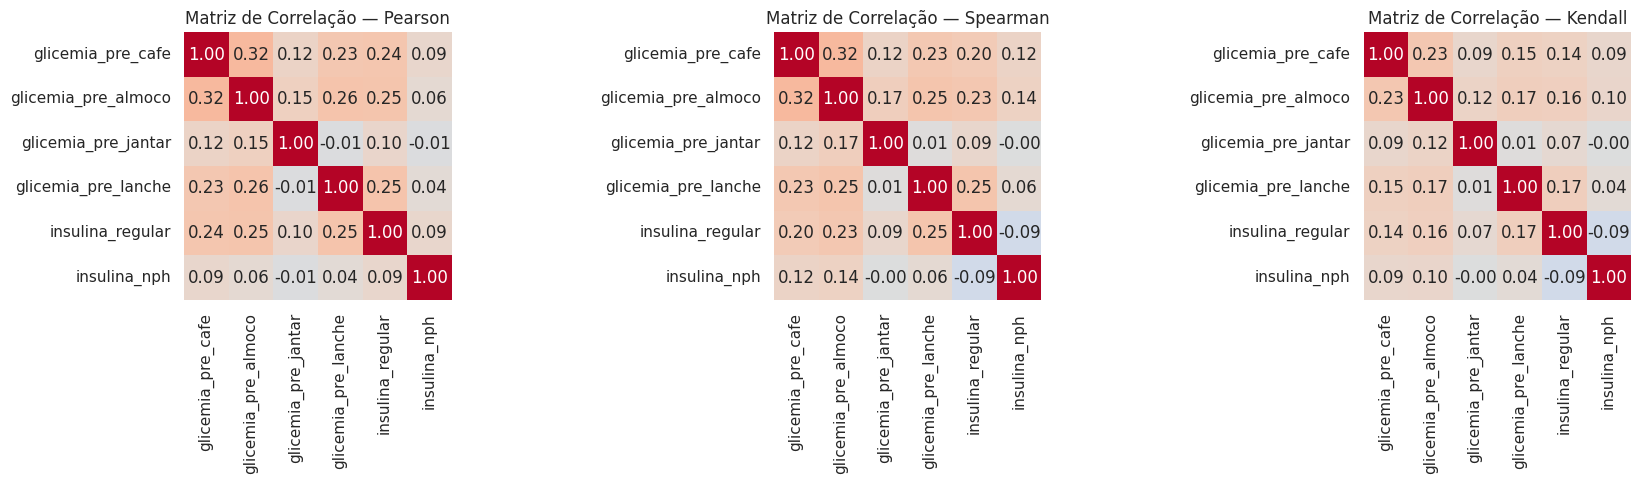

Maior divergência |Pearson - Spearman| por par:
insulina_nph         insulina_regular       0.179
                     glicemia_pre_almoco    0.075
insulina_regular     glicemia_pre_cafe      0.036
insulina_nph         glicemia_pre_cafe      0.027
glicemia_pre_lanche  glicemia_pre_jantar    0.022
dtype: float64


In [ ]:
corr_pearson  = largo.corr(method="pearson")
corr_spearman = largo.corr(method="spearman")
corr_kendall  = largo.corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (corr, nome) in zip(ax, [(corr_pearson, "Pearson"),
                                (corr_spearman, "Spearman"),
                                (corr_kendall, "Kendall")]):
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, ax=a, cbar=False)
    a.set_title(f"Matriz de Correlação — {nome}")
    a.set_xlabel("")
    a.set_ylabel("")

plt.tight_layout()
plt.show()

print("Maior divergência |Pearson - Spearman| por par:")
dif = (corr_pearson - corr_spearman).abs()
dif.values[np.triu_indices_from(dif, k=0)] = np.nan
print(dif.stack().sort_values(ascending=False).head(5).round(3))

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

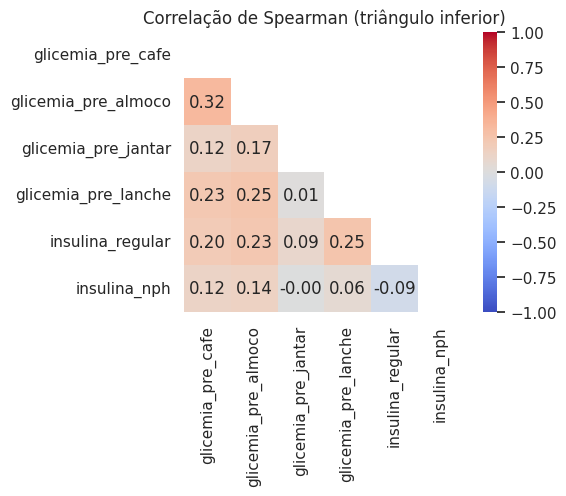

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm",
            fmt=".2f", square=True, vmin=-1, vmax=1)
plt.title("Correlação de Spearman (triângulo inferior)")
plt.grid(False)
plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, é sinal de relação não-linear, monotônica mas não em linha reta, que o Spearman captura e o Pearson não.

Olhem principalmente os pares que envolvem 'insulina_regular'. É a série com skewness de 26 e kurtosis de 1580, e o Pearson é justamente o coeficiente sensível a cauda extrema. Se a divergência se concentrar ali, a explicação não é não-linearidade de verdade, são aqueles poucos valores extremos puxando o Pearson.

Uma limitação que vale registrar: o '.corr()' do pandas usa exclusão par a par, então cada célula da matriz foi calculada sobre um conjunto diferente de paciente-dias. Nem todo paciente mediu glicemia em todos os momentos e todos os dias, e os percentuais de preenchimento impressos ali em cima mostram o tamanho do problema. Coeficiente calculado sobre base diferente não é estritamente comparável entre si. É o tipo de ressalva que precisa aparecer no relatório, e não ficar implícita no código.

#### Dispersão (scatter) entre duas variáveis quantitativas

A gente escolheu **dose de insulina NPH no dia × glicemia pré-café do dia seguinte** por um motivo de domínio, e não só estatístico. A NPH é a insulina de ação lenta, aplicada pra cobrir o período em que o paciente tá dormindo. E a glicemia de jejum na manhã seguinte é exatamente o desfecho que essa dose deveria controlar. Ou seja, é o par onde existe uma relação fisiológica esperada, e não só uma associação numérica.

Repara que esse par exige montar uma defasagem de um dia. Isso é uma diferença importante em relação a um dataset tabular clássico: aqui as duas variáveis não estão na mesma linha por natureza, elas estão separadas no tempo. E é a pergunta clínica que define qual defasagem faz sentido usar.

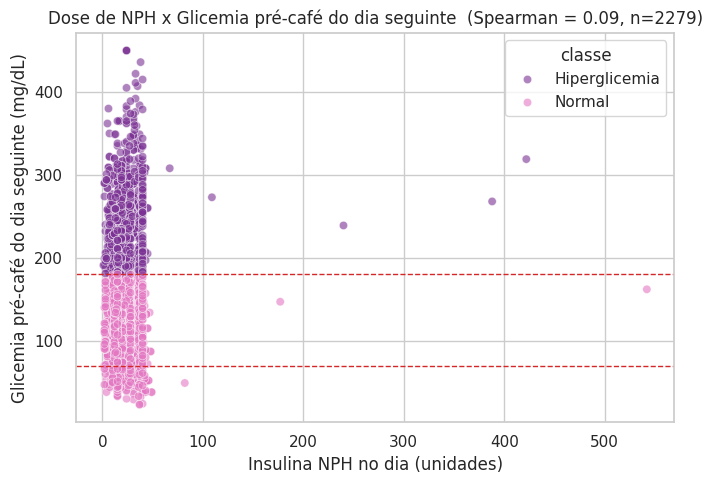

In [ ]:
pares = largo.reset_index().sort_values(["paciente", "dia"]).copy()

pares["glic_manha_seguinte"] = pares.groupby("paciente")["glicemia_pre_cafe"].shift(-1)
pares["dia_seguinte"] = pares.groupby("paciente")["dia"].shift(-1)

pares["gap"] = (pd.to_datetime(pares["dia_seguinte"]) - pd.to_datetime(pares["dia"])).dt.days
pares = pares[pares["gap"] == 1]

scatter = pares.dropna(subset=["insulina_nph", "glic_manha_seguinte"]).copy()
scatter["classe"] = np.where(scatter["glic_manha_seguinte"] > 180, "Hiperglicemia", "Normal")

rho = scatter["insulina_nph"].corr(scatter["glic_manha_seguinte"], method="spearman")

plt.figure(figsize=(7, 5))
sns.scatterplot(data=scatter, x="insulina_nph", y="glic_manha_seguinte",
                hue="classe",
                palette={"Normal": COR_CONTEXTO, "Hiperglicemia": COR_DESTAQUE},
                alpha=0.6)
plt.axhline(180, color=COR_ALERTA, linestyle="--", linewidth=1)
plt.axhline(70, color=COR_ALERTA, linestyle="--", linewidth=1)
plt.title(f"Dose de NPH x Glicemia pré-café do dia seguinte  (Spearman = {rho:.2f}, n={len(scatter)})")
plt.xlabel("Insulina NPH no dia (unidades)")
plt.ylabel("Glicemia pré-café do dia seguinte (mg/dL)")
plt.tight_layout()
plt.show()

**Pra discutir:** dá pra ver alguma tendência, tipo conforme a dose de NPH aumenta a glicemia da manhã seguinte tende a cair? As duas classes ocupam regiões diferentes do gráfico ou estão misturadas?

Antes de responder, tem uma armadilha que esse par expõe melhor do que qualquer outro do dataset. Se a correlação sair **positiva** (mais insulina, glicemia mais alta), a leitura ingênua seria "insulina piora a glicemia", o que obviamente é falso. O que tá acontecendo ali é causalidade reversa: paciente que já vinha descompensado recebe dose maior, e continua mais alto no dia seguinte. A dose é consequência do quadro, não só causa dele.

É o exemplo mais limpo da aula de que correlação bivariada não isola efeito. Pra responder a pergunta clínica de verdade, seria preciso comparar cada paciente com ele mesmo ao longo do tempo, e não empilhar todo mundo num scatter só. O gráfico tá misturando 70 pessoas com necessidades basais completamente diferentes.

Repara também na nuvem horizontal: a dispersão vertical em qualquer faixa de dose é enorme. Isso já diz que a dose sozinha explica pouco da glicemia da manhã, o que bate com o que se sabe do domínio, já que alimentação, atividade e estresse também entram na conta.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada a gente listou o **T-Test** (2 grupos) e a **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias. Só que os dois assumem normalidade dentro de cada grupo.

E já vimos na Seção 3, naquela tabela generalizada do Shapiro-Wilk, que **nenhuma** das nossas séries de medição passou nesse teste. Ou seja, tecnicamente a gente deveria usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveria ser reportado como principal.

**E tem uma escolha deliberada aqui de qual comparação fazer.** O caminho óbvio seria comparar 'valor' entre 'Normal' e 'Hiperglicemia', e isso seria um erro. Essas duas classes foram criadas *a partir do próprio* 'valor', com corte em 180 mg/dL. Testar se elas diferem é testar se número acima de 180 é maior que número abaixo de 180. O p-valor sairia praticamente zero e não significaria nada. É circularidade, e é bem fácil de cometer sem perceber quando o alvo é derivado.

Em vez disso, a gente compara a glicemia entre **momentos do dia**, que são categorias registradas de forma independente da medição.

In [ ]:
glic["momento"] = glic["evento"].str.replace("glicemia_", "", regex=False)

resultados_comparacao = []
pares = [("pre_cafe", "pre_jantar"), ("pre_cafe", "pre_almoco"), ("pre_almoco", "pre_jantar")]

for a, b in pares:
    grupo_a = glic.loc[glic["momento"] == a, "valor"].dropna()
    grupo_b = glic.loc[glic["momento"] == b, "valor"].dropna()

    stat_t, p_t = stats.ttest_ind(grupo_a, grupo_b, equal_var=False)   # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_a, grupo_b)                 # não-paramétrico

    resultados_comparacao.append({
        "comparacao": f"{a} x {b}",
        "n_a": len(grupo_a),
        "n_b": len(grupo_b),
        "mediana_a": round(grupo_a.median(), 1),
        "mediana_b": round(grupo_b.median(), 1),
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("comparacao")

,n_a,n_b,mediana_a,mediana_b,p_valor_ttest,p_valor_mannwhitney,concordam
comparacao,,,,,,,
pre_cafe x pre_jantar,3518,3158,161.0,147.0,0.0,0.0,True
pre_cafe x pre_almoco,3518,2768,161.0,134.0,0.0,0.0,True
pre_almoco x pre_jantar,2768,3158,134.0,147.0,0.0,0.0,True


**Pra discutir:** os dois testes concordam nas três comparações, ou seja, os dois deram significativo ou os dois não deram? Quando divergirem, é o **Mann-Whitney** que a gente deveria priorizar. É ele que respeita a premissa que de fato temos (dados não-normais), e não a que a gente gostaria de ter.

**Nota:** o T-Test ficou aqui só como contraste pedagógico. Reportar só o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas séries.

**E tem uma segunda ressalva, mais séria que a da normalidade:** os dois testes assumem observações independentes, e as nossas não são. As medições vêm de 70 pacientes, cada um contribuindo com centenas de registros. Com n na casa dos milhares, qualquer diferença mínima vira "significativa". O p-valor tá medindo o tamanho da amostra tanto quanto o tamanho do efeito. Olhem as medianas na tabela, ali do lado dos p-valores: o que importa é a diferença clínica, não o asterisco.

*Exemplo com 3+ grupos: ANOVA x Kruskal-Wallis*

O 'momento' tem 6 categorias (pré e pós de café, almoço e jantar). Pelo mesmo motivo de antes, a gente calcula a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, o equivalente pra 3+ grupos) lado a lado.

ANOVA          — glicemia entre momentos do dia: estatística=62.375, p-valor=3.0761e-64
Kruskal-Wallis — glicemia entre momentos do dia: estatística=280.839, p-valor=1.3144e-58


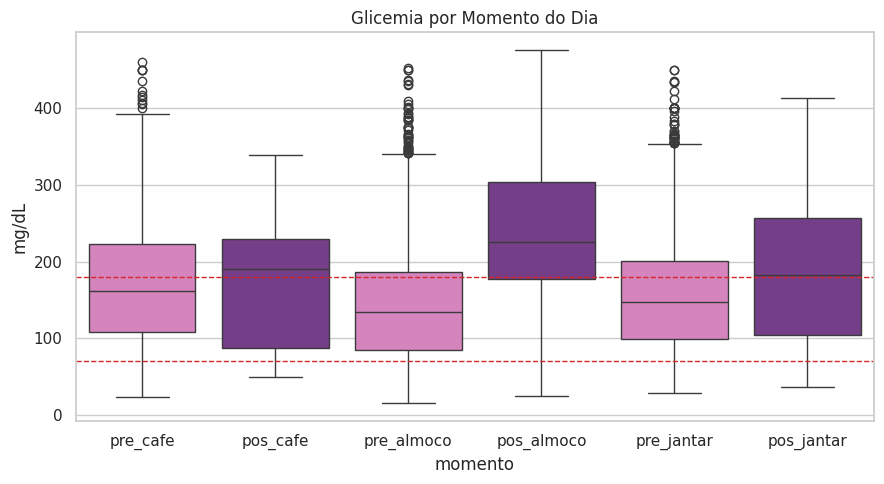

In [ ]:
MOMENTOS_ORD = ["pre_cafe", "pos_cafe", "pre_almoco", "pos_almoco", "pre_jantar", "pos_jantar"]
comp = glic[glic["momento"].isin(MOMENTOS_ORD)].copy()

grupos_momento = [g["valor"].dropna().values for _, g in comp.groupby("momento")]

stat_anova, p_anova = stats.f_oneway(*grupos_momento)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_momento)          # não-paramétrico

print(f"ANOVA          — glicemia entre momentos do dia: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — glicemia entre momentos do dia: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

paleta = {m: (COR_DESTAQUE if m.startswith("pos") else COR_CONTEXTO) for m in MOMENTOS_ORD}

plt.figure(figsize=(9, 5))
sns.boxplot(data=comp, x="momento", y="valor", hue="momento",
            order=MOMENTOS_ORD, palette=paleta, legend=False)
plt.axhline(180, color=COR_ALERTA, linestyle="--", linewidth=1)
plt.axhline(70, color=COR_ALERTA, linestyle="--", linewidth=1)
plt.title("Glicemia por Momento do Dia")
plt.ylabel("mg/dL")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos um momento do dia? Como a gente já sabe que a glicemia não é normal, o **Kruskal-Wallis** é o resultado que deveria ser reportado como principal, e a ANOVA fica só de contraste.

E repara no que o teste *não* responde: ele diz que pelo menos um grupo difere, mas não diz qual. Pra saber isso seria preciso um pós-teste (Dunn, com correção pra múltiplas comparações). O boxplot já dá uma pista de onde tá a diferença, então compara as medianas dos pós-refeição com as dos pré.

#### Quantitativa x Qualitativa

Qui-Quadrado: estatística=205.24, gl=5, p-valor=2.152e-42
V de Cramér: 0.145  (0 = sem associação, 1 = associação perfeita)


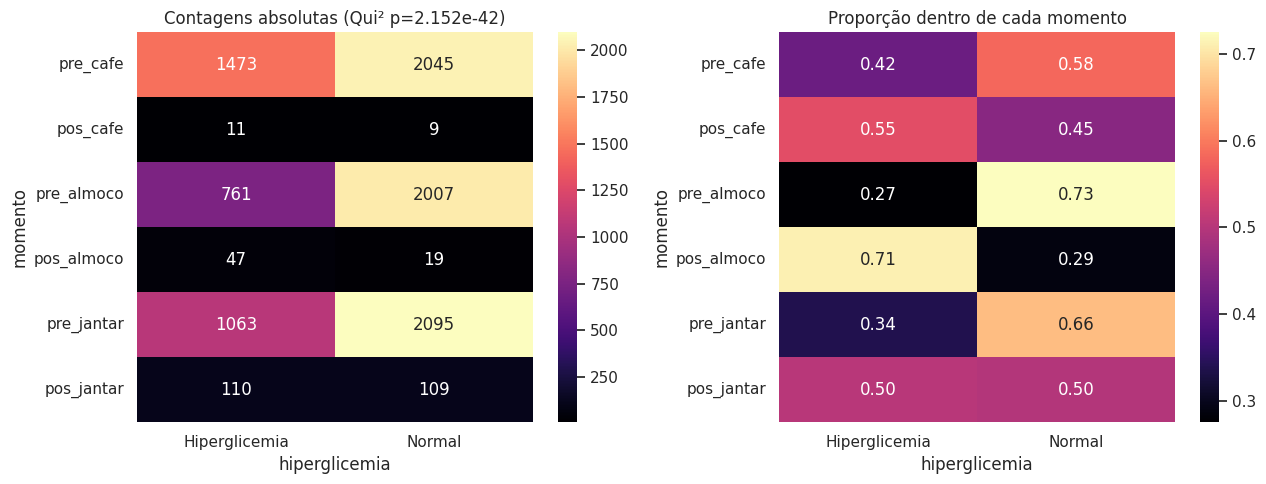

In [ ]:
contingencia = pd.crosstab(comp["momento"], comp["hiperglicemia"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia)

n = contingencia.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingencia.shape) - 1)))

print(f"Qui-Quadrado: estatística={chi2:.2f}, gl={gl}, p-valor={p_chi2:.4g}")
print(f"V de Cramér: {cramers_v:.3f}  (0 = sem associação, 1 = associação perfeita)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(contingencia.reindex(MOMENTOS_ORD), annot=True, fmt="d",
            cmap="magma", ax=axes[0])
axes[0].set_title(f"Contagens absolutas (Qui² p={p_chi2:.4g})")

prop = contingencia.reindex(MOMENTOS_ORD).div(
    contingencia.reindex(MOMENTOS_ORD).sum(axis=1), axis=0)
sns.heatmap(prop, annot=True, fmt=".2f", cmap="magma", ax=axes[1])
axes[1].set_title("Proporção dentro de cada momento")

plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que 'momento' e 'hiperglicemia' são independentes, ou que existe associação estatisticamente significativa entre as duas?

Com n na casa dos milhares, a resposta quase certamente vai ser "significativa", e é justamente por isso que o **V de Cramér** aparece junto. O p-valor responde "existe alguma associação?", o V de Cramér responde "de que tamanho?". São perguntas diferentes, e só a segunda é clinicamente útil. Um V de 0,05 com p < 0,001 quer dizer que a associação existe e é minúscula.

Repara também que o painel da direita, o das proporções, conta uma história que o da esquerda esconde. As contagens absolutas são dominadas pelos momentos com mais registros. O 'pos_cafe' tem 20 medições e o 'pre_cafe' tem milhares, então a célula do 'pos_cafe' fica escura no heatmap de contagens mesmo que a proporção de hiperglicemia ali seja alta. Normalizar por linha é o que deixa os momentos comparáveis entre si.

E uma ressalva de premissa: o Qui-Quadrado assume observações independentes, e as nossas vêm de 70 pacientes com centenas de registros cada um. A tabela tá tratando 13 mil medições como se fossem 13 mil sujeitos diferentes, o que infla a estatística. É a mesma limitação dos testes anteriores, e vale registrar isso no relatório em vez de deixar implícito.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta que aparece bastante em discussão de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis? Se não, isso pode refletir um padrão real ou um viés na forma como os dados foram coletados. De qualquer jeito, é algo que vale mapear **antes** de qualquer modelagem.

**E aqui a gente esbarra numa limitação do dataset, que por si só já é o achado de fairness.** O Diabetes do UCI não traz nenhum atributo demográfico. Não tem idade, sexo, raça, renda ou região. Cada paciente é só um número de 1 a 70. Ou seja, não dá pra verificar se o modelo trataria homens e mulheres de forma diferente, porque a gente nem sabe quem é quem.

Isso não é um detalhe técnico, é uma falha de auditabilidade. Um modelo treinado nesses dados pode ter todo tipo de viés demográfico embutido e não teríamos como detectar. "Não coletamos o atributo sensível" não torna o sistema justo, torna a injustiça invisível. É um padrão bem comum em dataset clínico antigo, e vale registrar isso explicitamente no relatório em vez de simplesmente pular a seção.

O que a gente *consegue* auditar é a **representatividade**, ou seja, quem tá sobre-representado nos dados. Com 70 pacientes contribuindo com números bem diferentes de registros, qualquer estatística agregada tá ponderada por quem registrou mais. E quem registra mais provavelmente não é uma amostra aleatória da população de diabéticos.

In [ ]:
por_paciente = (
    glic.groupby("paciente")
        .agg(n_medicoes=("valor", "size"),
             glicemia_mediana=("valor", "median"),
             pct_hiper=("hiperglicemia", lambda s: (s == "Hiperglicemia").mean()))
        .sort_values("n_medicoes", ascending=False)
)

n_total = por_paciente["n_medicoes"].sum()
top10 = por_paciente.head(10)["n_medicoes"].sum()
bottom10 = por_paciente.tail(10)["n_medicoes"].sum()

print("--- Representatividade dos pacientes ---")
print(f"Total de medições de glicemia : {n_total}")
print(f"Média por paciente            : {por_paciente['n_medicoes'].mean():.1f}")
print(f"Mediana por paciente          : {por_paciente['n_medicoes'].median():.1f}")
print(f"Mínimo / Máximo               : {por_paciente['n_medicoes'].min()} / {por_paciente['n_medicoes'].max()}")
print(f"Razão máx/mín                 : {por_paciente['n_medicoes'].max() / por_paciente['n_medicoes'].min():.1f}x")
print(f"\n10 pacientes mais registrados: {top10} medições ({100*top10/n_total:.1f}% do total)")
print(f"10 pacientes menos registrados: {bottom10} medições ({100*bottom10/n_total:.1f}% do total)")

--- Representatividade dos pacientes ---
Total de medições de glicemia : 13522
Média por paciente            : 193.2
Mediana por paciente          : 120.0
Mínimo / Máximo               : 31 / 616
Razão máx/mín                 : 19.9x

10 pacientes mais registrados: 5238 medições (38.7% do total)
10 pacientes menos registrados: 674 medições (5.0% do total)


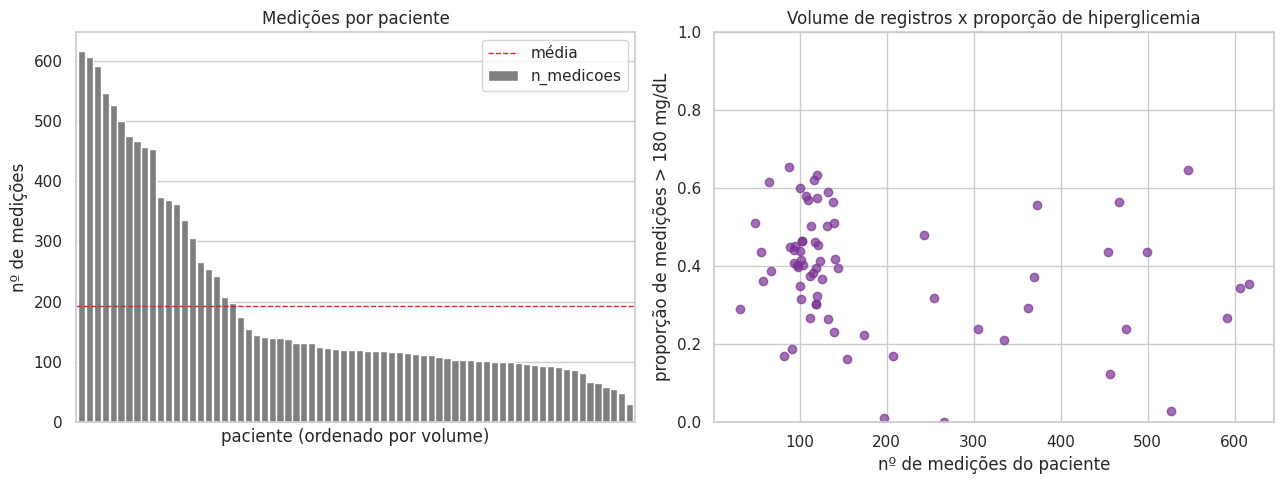

Spearman entre volume de registros e proporção de hiperglicemia: -0.259


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

por_paciente["n_medicoes"].plot(kind="bar", color=COR_NEUTRA, ax=axes[0], width=0.9)
axes[0].axhline(por_paciente["n_medicoes"].mean(), color=COR_ALERTA,
                linestyle="--", linewidth=1, label="média")
axes[0].set_title("Medições por paciente")
axes[0].set_xlabel("paciente (ordenado por volume)")
axes[0].set_ylabel("nº de medições")
axes[0].set_xticks([])
axes[0].legend()

axes[1].scatter(por_paciente["n_medicoes"], por_paciente["pct_hiper"],
                color=COR_DESTAQUE, alpha=0.7)
axes[1].set_title("Volume de registros x proporção de hiperglicemia")
axes[1].set_xlabel("nº de medições do paciente")
axes[1].set_ylabel("proporção de medições > 180 mg/dL")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

rho_repr = por_paciente["n_medicoes"].corr(por_paciente["pct_hiper"], method="spearman")
print(f"Spearman entre volume de registros e proporção de hiperglicemia: {rho_repr:.3f}")

In [ ]:
media_ponderada = glic["valor"].mean()
media_por_paciente = por_paciente_mediana = glic.groupby("paciente")["valor"].mean().mean()

print(f"Média de glicemia agregando todas as medições : {media_ponderada:.2f} mg/dL")
print(f"Média das médias por paciente (1 voto cada)   : {media_por_paciente:.2f} mg/dL")
print(f"Diferença                                    : {abs(media_ponderada - media_por_paciente):.2f} mg/dL")

Média de glicemia agregando todas as medições : 160.26 mg/dL
Média das médias por paciente (1 voto cada)   : 162.55 mg/dL
Diferença                                    : 2.29 mg/dL


**Pra discutir:** a contribuição de cada paciente pro dataset é uniforme? O gráfico da esquerda responde: não. Alguns pacientes registraram muitas vezes mais que outros, e o agregado reflete esses poucos de forma desproporcional.

Já o gráfico da direita faz a pergunta que realmente importa: **quem registra mais é sistematicamente diferente de quem registra menos?** Se tiver correlação entre volume de registros e proporção de hiperglicemia, o viés não é neutro, porque o dataset estaria super-amostrando um perfil clínico específico. Tem duas explicações plausíveis e opostas: ou pacientes mais descompensados são orientados a medir mais vezes (e aí a média agregada puxaria pra cima), ou pacientes mais aderentes ao tratamento medem mais e também se controlam melhor (e aí puxaria pra baixo).

A comparação final é o que quantifica o efeito: a média agregando todas as medições contra a média das médias por paciente, onde cada pessoa vale um voto. Se as duas diferem, a primeira não descreve "a glicemia típica de um diabético tipo 1", descreve a glicemia típica de quem registrou mais.

--- Quem registra mais tem perfil clínico diferente? ---
Muitos registros (n=33): mediana de hiperglicemia = 0.356
Poucos registros (n=37): mediana de hiperglicemia = 0.416
Mann-Whitney U: p-valor = 0.02111
Conclusão: perfis diferentes (alpha=0.05)


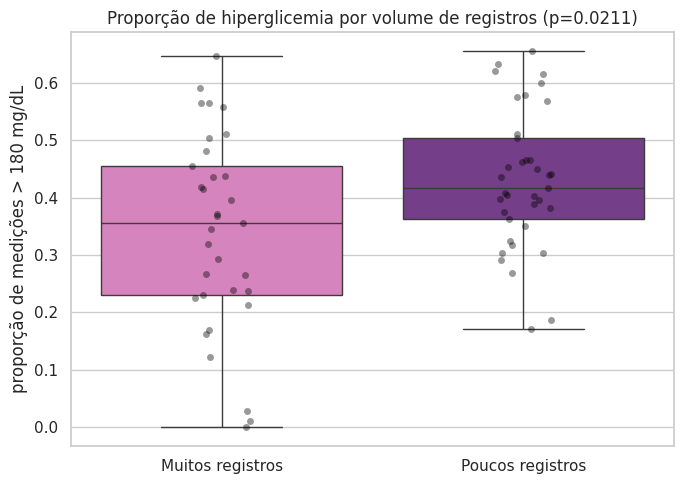

In [ ]:
mediana_vol = por_paciente["n_medicoes"].median()
por_paciente["grupo_volume"] = np.where(
    por_paciente["n_medicoes"] > mediana_vol, "Muitos registros", "Poucos registros")

g_muitos = por_paciente.loc[por_paciente["grupo_volume"] == "Muitos registros", "pct_hiper"]
g_poucos = por_paciente.loc[por_paciente["grupo_volume"] == "Poucos registros", "pct_hiper"]

stat_u, p_u = stats.mannwhitneyu(g_muitos, g_poucos)

print("--- Quem registra mais tem perfil clínico diferente? ---")
print(f"Muitos registros (n={len(g_muitos)}): mediana de hiperglicemia = {g_muitos.median():.3f}")
print(f"Poucos registros (n={len(g_poucos)}): mediana de hiperglicemia = {g_poucos.median():.3f}")
print(f"Mann-Whitney U: p-valor = {p_u:.4g}")
print(f"Conclusão: {'perfis diferentes' if p_u < 0.05 else 'sem evidência de diferença'} (alpha=0.05)")

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=por_paciente.reset_index(), x="grupo_volume", y="pct_hiper",
            hue="grupo_volume", palette=[COR_CONTEXTO, COR_DESTAQUE], legend=False, ax=ax)
sns.stripplot(data=por_paciente.reset_index(), x="grupo_volume", y="pct_hiper",
              color="black", alpha=0.4, ax=ax)
ax.set_title(f"Proporção de hiperglicemia por volume de registros (p={p_u:.3g})")
ax.set_xlabel("")
ax.set_ylabel("proporção de medições > 180 mg/dL")
plt.tight_layout()
plt.show()

**Pra discutir:** o teste aponta diferença entre quem registrou muito e quem registrou pouco? Lembrando que, mesmo que a diferença seja estatisticamente significativa, isso não diz *por que* ela existe. Pode ser que pacientes mais descompensados sejam orientados a medir mais vezes, pode ser que pacientes mais aderentes meçam mais e também se controlem melhor, ou pode ser uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela. Essa distinção é o núcleo de qualquer discussão séria de fairness.

Repara que aqui o n é 70 e não 13 mil, porque cada paciente entra uma vez só. É a única comparação da aula em que a premissa de independência está de fato satisfeita. E não é à toa que é também a única em que o p-valor significa alguma coisa. Compara com a tabela de Shapiro da Seção 3, onde justamente as agregações por paciente (n=70) foram as únicas que não rejeitaram normalidade.

#### Outliers bivariados

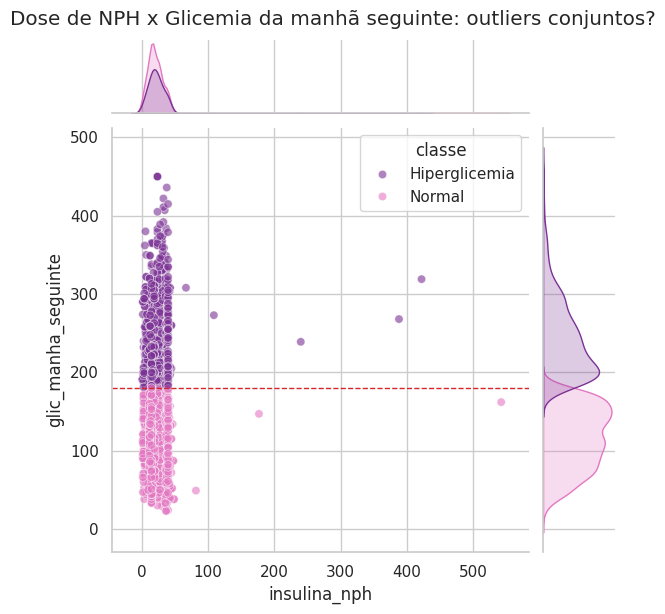

Paciente-dias com combinação extrema: 7
      paciente         dia  insulina_nph  glic_manha_seguinte
516         11  1990-07-23          43.0                308.0
537         12  1990-07-23          43.0                308.0
560         12  1990-08-16          67.0                308.0
1182        24  1991-07-05          42.0                303.0
2078        37  1991-05-07           5.0                362.0
2973        55  1991-07-16           4.0                301.0
3427        65  1989-06-27         422.0                319.0


In [ ]:
g = sns.jointplot(data=scatter, x="insulina_nph", y="glic_manha_seguinte",
                  hue="classe",
                  palette={"Normal": COR_CONTEXTO, "Hiperglicemia": COR_DESTAQUE},
                  alpha=0.6, height=6)
g.ax_joint.axhline(180, color=COR_ALERTA, linestyle="--", linewidth=1)
g.figure.suptitle("Dose de NPH x Glicemia da manhã seguinte: outliers conjuntos?", y=1.02)
plt.show()

q_nph = scatter["insulina_nph"].quantile([0.05, 0.95])
q_glic = scatter["glic_manha_seguinte"].quantile([0.05, 0.95])

conjuntos = scatter[
    ((scatter["insulina_nph"] > q_nph[0.95]) & (scatter["glic_manha_seguinte"] > q_glic[0.95])) |
    ((scatter["insulina_nph"] < q_nph[0.05]) & (scatter["glic_manha_seguinte"] > q_glic[0.95]))
]

print(f"Paciente-dias com combinação extrema: {len(conjuntos)}")
if len(conjuntos):
    print(conjuntos[["paciente", "dia", "insulina_nph", "glic_manha_seguinte"]].head(10))

**Pra discutir:** tem algum ponto que não parecia outlier nas distribuições univariadas (Seção 3 e 4), mas que aqui se destaca como uma combinação incomum de dose e glicemia?

Duas regiões merecem atenção, e elas querem dizer coisas opostas. **Dose alta com glicemia alta** é o paciente descompensado: a dose grande é resposta ao quadro ruim, e mesmo assim não foi suficiente. Já **dose baixa com glicemia alta** é o caso clinicamente mais preocupante, porque sugere dose insuficiente, esquecimento ou registro incompleto do diário.

O ponto pedagógico aqui é que nenhum desses valores é outlier sozinho. Uma dose de 20 unidades é normal. Uma glicemia de 300 mg/dL é normal *pra esse dataset*. O que carrega informação é a combinação das duas, e nenhuma análise univariada ia encontrar isso. É o argumento central pra fazer análise bivariada antes de decidir tratamento de outliers.

Os marginais do jointplot também valem uma olhada. Eles mostram as mesmas distribuições que vocês já viram nos histogramas da Seção 3, mas agora separadas por classe e alinhadas com o scatter. É a mesma informação vista de três jeitos ao mesmo tempo.

#### Análise Multivariada

##### Matriz de Correlação

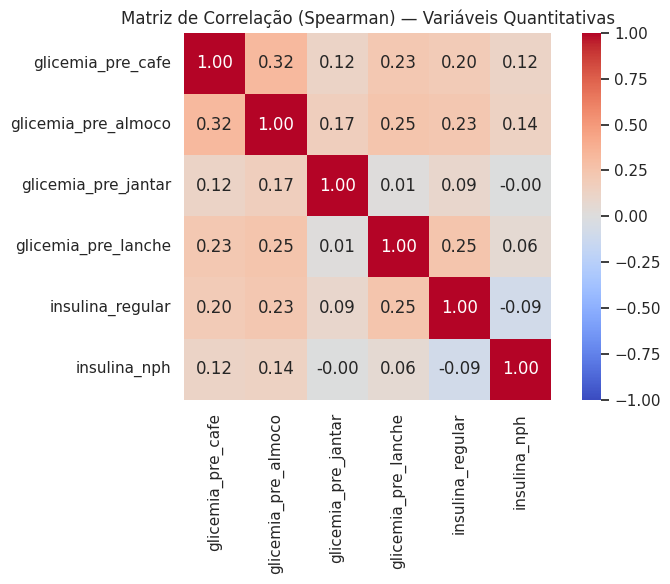

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(largo.corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*   |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

Repara que essa matriz só existe por causa do formato **paciente-dia**. No formato original, com uma linha por evento, só tem uma coluna numérica, e correlacionar 'valor' com ela mesma dá 1,00 num quadradinho só. Vale registrar isso no relatório: não é que o dataset não tenha estrutura de correlação, é que ela só aparece depois de reorganizar os dados na granularidade certa. E escolher essa granularidade é uma decisão analítica, não um passo mecânico. No nível paciente-dia a gente tá perguntando "dias com glicemia alta de manhã também têm glicemia alta à noite?", e no nível paciente seria "pacientes mais descompensados de manhã também são à noite?". São perguntas diferentes e dariam matrizes diferentes.

E uma ressalva sobre redundância: se 'glicemia_pre_almoco' e 'glicemia_pre_jantar' saírem fortemente correlacionadas, a leitura não é necessariamente "uma delas é dispensável". Pode ser simplesmente que o paciente teve um dia bom ou um dia

##### Correlograma

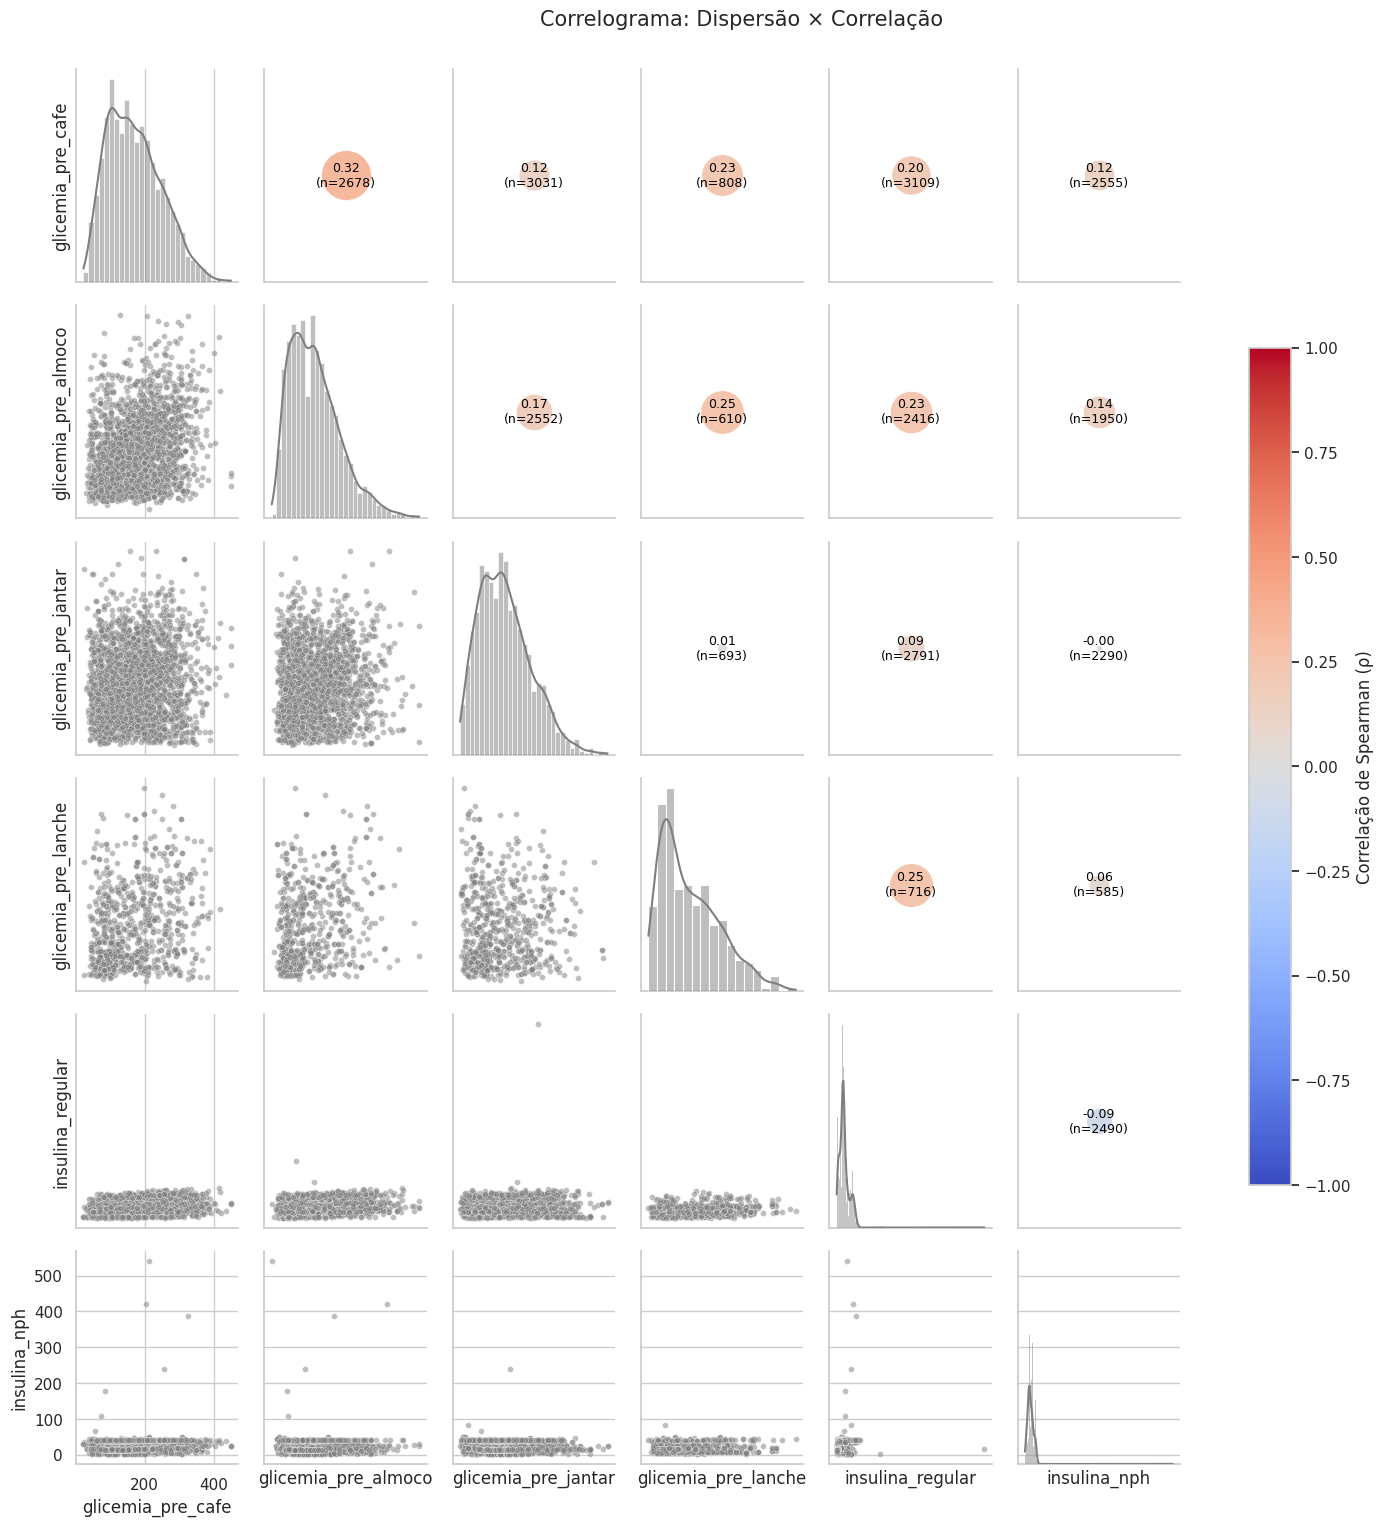

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    x = pd.Series(x)
    y = pd.Series(y)
    mask = x.notna() & y.notna()
    n = int(mask.sum())

    ax = plt.gca()
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

    if n < 3:
        ax.annotate("n/d", xy=(0.5, 0.5), xycoords=ax.transAxes,
                    ha="center", va="center", fontsize=10, color="gray")
        return

    r = stats.spearmanr(x[mask], y[mask]).correlation

    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap="coolwarm", vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}\n(n={n})", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=9,
                color="white" if abs(r) > 0.5 else "black")

g = sns.PairGrid(largo, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.5, s=18)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.figure.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman (ρ)")

g.figure.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)
plt.show()

#### Declaração IA

Usei para fazer os codigos em python/ seaborn e também para melhorar ainda mais minhas análises, por exemplo, eu tinha uma ideia, analisava e pedia pra ver se n tava deixando passar algo... Com relação a códigos eu dava ideia do que eu desejava, dizia o tipo de grafico que eu queria montar e pedia para o Claude gerar o codigo.